# **Project Name**    -

**Integrated Retail Analytics for Store Optimization and Demand Forecasting**

##### **Project Type**    - EDA/Regression/Classification/Unsupervised
##### **Contribution**    - Individual
#### **Team Member**      - ponna keerthi

# **Project Summary -**

The project titled **Integrated Retail Analytics for Store Optimization and Demand Forecasting** uses historical weekly retail sales, store attributes, promotional markdowns, and external economic and environmental variables to investigate sales performance and support operational decisions. The Sales dataset contains store-, department-, and week-level sales observations. The Features dataset contributes temperature, fuel price, markdowns, CPI, unemployment, and holiday information, while the Stores dataset provides store type and size. These sources are joined using the appropriate store and date keys to create an integrated analysis dataset.

The first stage focuses on data understanding and preprocessing. The datasets are inspected for dimensions, data types, duplicates, missing values, unique values, and descriptive statistics. Date fields are converted to datetime format and the data sources are integrated. Missing markdown values are treated as zero under the stated assumption that a missing value means no markdown was recorded; this assumption is documented because missingness may also reflect reporting practices. Missing economic indicators are reviewed in relation to the available date coverage. Feature engineering creates useful time fields such as year, month, and week of year, combines the five markdown fields into a total markdown measure, and retains store and department identifiers as meaningful predictors.

Exploratory Data Analysis uses at least 15 visualizations to examine overall weekly sales trends, sales distributions, store and department performance, store size, holiday and monthly patterns, markdown activity, and relationships between sales and external factors. Each chart is intended to answer a business question, describe the observed pattern, and explain potential operational implications. Three statistical hypotheses are also tested, covering holiday versus non-holiday sales, the relationship between store size and total sales, and differences in sales across store types. Statistical results should be interpreted with attention to practical importance and the dependence among repeated observations from the same stores and departments.

The forecasting component treats Weekly_Sales as a continuous prediction target and compares Ridge Regression, Random Forest Regression, and HistGradientBoosting Regression using MAE, RMSE, and R-squared. A chronological train/test split is used to better represent prediction of later periods from earlier observations. Hyperparameter search is performed for each model and baseline and tuned results are compared rather than assuming tuning must improve performance. Feature importance from the selected tree-based model helps describe which available predictors the model relies on; importance is predictive, not proof of causation. The selected model is saved and loaded from Google Drive, and a small prediction sanity check compares actual and predicted values.

The project also includes dedicated supplementary analyses for unusual sales observations and store segmentation. Potential anomalies are flagged for investigation rather than automatically deleted, because extreme sales can be genuine holiday or high-demand events. Stores are grouped using aggregated performance and store characteristics, and cluster quality is evaluated with a silhouette score where feasible. Since the available data has no customer identifiers, transaction baskets, or product-level purchase records, genuine customer segmentation and product-level market basket analysis cannot be performed. A department-level sales co-movement analysis is therefore presented only as a transparent proxy for exploratory cross-selling hypotheses, not as transaction-based association rules.

The business goal is to translate the findings into practical recommendations for inventory planning, staffing, promotional review, and store-level demand monitoring. The results are constrained by the historical period, available variables, missing-data assumptions, and the absence of customer/product transaction data. Before operational deployment, the workflow should be validated on newer periods, checked for data leakage, and reviewed with business stakeholders. Supporting documentation, reproducible code, a README, a view-accessible notebook, and a presentation video will accompany the final submission.

# **GitHub Link -**

**GitHub repository link:** _Add the final public repository URL here after the repository has been created and checked._

Do not leave this placeholder in the submitted notebook.

# **Problem Statement**


Retail stores generate large amounts of sales data across different stores and departments, but raw historical sales data alone does not provide clear insights into sales trends, unusual sales patterns, seasonal demand, or the factors influencing sales performance.
The objective of this project is to analyze weekly retail sales using store information, markdown data, and external factors such as temperature, fuel price, CPI, and unemployment. The analysis will identify sales anomalies, understand seasonal and holiday effects, segment stores or departments based on performance patterns, and develop demand forecasting models.
The insights obtained will be used to support practical decisions related to inventory management, marketing, demand planning, and store optimization.

#### **Define Your Business Objective?**

The primary objective is to use historical retail sales data to improve store performance and demand planning. The analysis aims to:
- Identify sales trends, seasonal patterns, holiday effects, and unusual sales behavior across stores and departments.
- Understand how markdowns, store characteristics, and external factors such as temperature, fuel price, CPI, and unemployment relate to weekly sales.
- Segment stores or departments based on their sales and performance characteristics.
- Forecast future weekly sales to support demand and inventory planning.
- Develop practical recommendations for store optimization, inventory management, and marketing strategies based on data-driven insights.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# IMPORT REQUIRED LIBRARIES
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Initial libraries imported successfully.")

Initial libraries imported successfully.


### Dataset Loading

In [2]:
# ============================================================
# LOAD DATASETS FROM GOOGLE DRIVE
# ============================================================

from google.colab import drive
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

# Path to the project folder in Google Drive
project_path = '/content/drive/MyDrive/Retail Analytics Project/'

# Load the three datasets
sales_df = pd.read_csv(project_path + 'sales data-set.csv')
features_df = pd.read_csv(project_path + 'Features data set.csv')
stores_df = pd.read_csv(project_path + 'stores data-set.csv')

print("Datasets loaded successfully from Google Drive.")

print("\nSales dataset:", sales_df.shape)
print("Features dataset:", features_df.shape)
print("Stores dataset:", stores_df.shape)

Mounted at /content/drive
Datasets loaded successfully from Google Drive.

Sales dataset: (421570, 5)
Features dataset: (8190, 12)
Stores dataset: (45, 3)


### Dataset First View

In [3]:
# Dataset First Look
# Load the three datasets
sales_df = pd.read_csv(project_path + 'sales data-set.csv')
features_df = pd.read_csv(project_path + 'Features data set.csv')
stores_df = pd.read_csv(project_path + 'stores data-set.csv')
# Display the first five rows of each dataset
print("========== SALES DATA ==========")
display(sales_df.head())

print("========== FEATURES DATA ==========")
display(features_df.head())

print("========== STORES DATA ==========")
display(stores_df.head())

========== SALES DATA ==========


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,05/02/2010,24924.50,False
1,1,1,12/02/2010,46039.49,True
2,1,1,19/02/2010,41595.55,False
3,1,1,26/02/2010,19403.54,False
4,1,1,05/03/2010,21827.90,False


========== FEATURES DATA ==========


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,05/02/2010,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,12/02/2010,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,19/02/2010,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,26/02/2010,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,05/03/2010,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


========== STORES DATA ==========


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
# Display the number of rows and columns for each dataset

print("Sales Dataset:")
print("Rows:", sales_df.shape[0])
print("Columns:", sales_df.shape[1])

print("\nFeatures Dataset:")
print("Rows:", features_df.shape[0])
print("Columns:", features_df.shape[1])

print("\nStores Dataset:")
print("Rows:", stores_df.shape[0])
print("Columns:", stores_df.shape[1])

Sales Dataset:
Rows: 421570
Columns: 5

Features Dataset:
Rows: 8190
Columns: 12

Stores Dataset:
Rows: 45
Columns: 3


### Dataset Information

In [5]:
# Dataset Info
print("========== SALES DATA ==========")
sales_df.info()

print("\n========== FEATURES DATA ==========")
features_df.info()

print("\n========== STORES DATA ==========")
stores_df.info()

========== SALES DATA ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB

========== FEATURES DATA ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         8190 non-null   int64  
 1   Date          8190 non-null   object 
 2   Temperature   8190 non-null   float64
 3   Fuel_Price    8190 non-null   float64
 4   MarkDown1     4032 non-null   float64
 5   MarkDown2     2921 non-null

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
# Check the number of completely duplicated rows in each dataset
sales_duplicates = sales_df.duplicated().sum()
features_duplicates = features_df.duplicated().sum()
stores_duplicates = stores_df.duplicated().sum()

print("Sales Dataset - Duplicate Rows:", sales_duplicates)
print("Features Dataset - Duplicate Rows:", features_duplicates)
print("Stores Dataset - Duplicate Rows:", stores_duplicates)

Sales Dataset - Duplicate Rows: 0
Features Dataset - Duplicate Rows: 0
Stores Dataset - Duplicate Rows: 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
# Calculate the number of missing values in each column
# for all three datasets.

print("========== SALES DATA - MISSING VALUES ==========")
display(sales_df.isnull().sum())

print("\n========== FEATURES DATA - MISSING VALUES ==========")
display(features_df.isnull().sum())

print("\n========== STORES DATA - MISSING VALUES ==========")
display(stores_df.isnull().sum())

========== SALES DATA - MISSING VALUES ==========


,0
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday,0



========== FEATURES DATA - MISSING VALUES ==========


,0
Store,0
Date,0
Temperature,0
Fuel_Price,0
MarkDown1,4158
MarkDown2,5269
MarkDown3,4577
MarkDown4,4726
MarkDown5,4140
CPI,585



========== STORES DATA - MISSING VALUES ==========


,0
Store,0
Type,0
Size,0


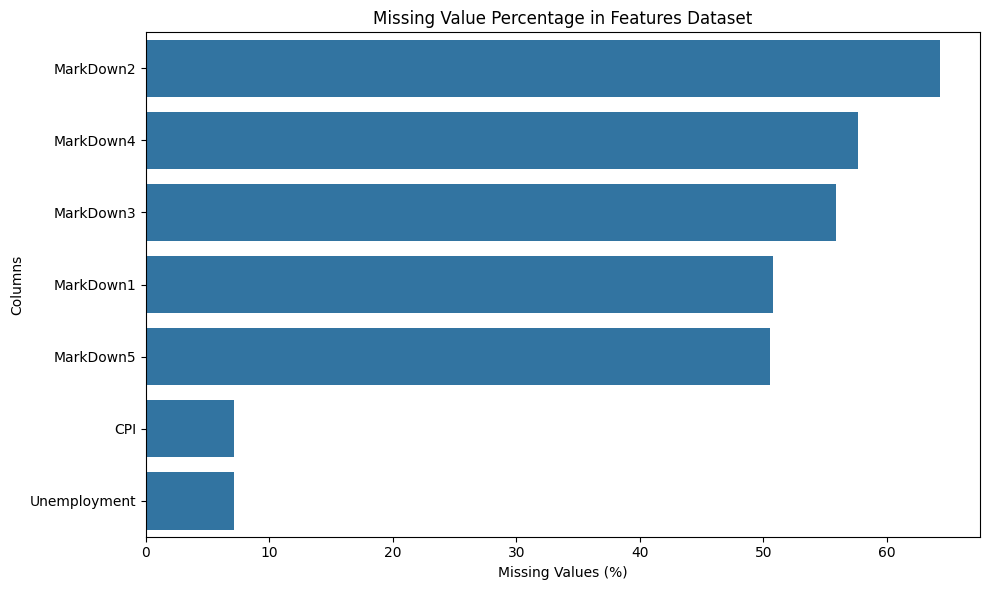

In [8]:
# Visualizing the missing values
# Calculate missing-value percentages for the Features dataset
missing_percentage = (
    features_df.isnull().mean() * 100
).sort_values(ascending=False)

# Keep only columns that contain missing values
missing_percentage = missing_percentage[missing_percentage > 0]

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=missing_percentage.values,
    y=missing_percentage.index
)

plt.title("Missing Value Percentage in Features Dataset")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

**Chart Insight**:

**Why was this chart selected?**:

A horizontal bar chart was selected to compare the percentage of missing values across the affected columns in the Features dataset.

**What insights were found?**:

The Markdown variables have substantial missing values. MarkDown2 has the highest missing percentage at approximately 64%, followed by MarkDown4, MarkDown3, MarkDown1, and MarkDown5. CPI and Unemployment have comparatively lower missing values of approximately 7% each.

**Business impact:**

Missing Markdown information can affect the analysis of promotional activity and its relationship with weekly sales. Therefore, the missing values need to be investigated and handled appropriately during preprocessing before using these variables for further analysis or modeling.

**Assumption and limitation:** missing markdown entries were filled with zero as a proxy for no recorded markdown activity. This is a practical assumption, not proof that no markdown occurred; verify against source-system definitions if available.

### What did you know about your dataset?

The project contains three related datasets: Sales, Features, and Stores. The Sales dataset contains 421,570 records with weekly sales information at store and department level. The Features dataset contains 8,190 records with store-date information, temperature, fuel price, five Markdown variables, CPI, unemployment, and holiday information. The Stores dataset contains information for 45 stores, including store type and store size.
The initial analysis shows that there are no completely duplicated rows in any of the three datasets. The Sales and Stores datasets have no missing values, while the Features dataset contains substantial missing values in the Markdown variables and some missing values in CPI and Unemployment. These data-quality issues will need to be investigated and appropriately handled during the preprocessing stage.
The datasets can be connected using common fields such as Store and Date, which will allow us to combine sales information with store characteristics and external factors for further analysis.Answer Here

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
print("========== SALES DATA COLUMNS ==========")
print(sales_df.columns.tolist())

print("\n========== FEATURES DATA COLUMNS ==========")
print(features_df.columns.tolist())

print("\n========== STORES DATA COLUMNS ==========")
print(stores_df.columns.tolist())

========== SALES DATA COLUMNS ==========
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']

========== FEATURES DATA COLUMNS ==========
['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']

========== STORES DATA COLUMNS ==========
['Store', 'Type', 'Size']


In [10]:
# Dataset Describe
print("========== SALES DATA DESCRIBE ==========")
display(sales_df.describe())

print("\n========== FEATURES DATA DESCRIBE ==========")
display(features_df.describe())

print("\n========== STORES DATA DESCRIBE ==========")
display(stores_df.describe())

========== SALES DATA DESCRIBE ==========


,Store,Dept,Weekly_Sales
count,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,15981.258123
std,12.785297,30.492054,22711.183519
min,1.000000,1.000000,-4988.940000
25%,11.000000,18.000000,2079.650000
50%,22.000000,37.000000,7612.030000
75%,33.000000,74.000000,20205.852500
max,45.000000,99.000000,693099.360000



========== FEATURES DATA DESCRIBE ==========


,Store,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
count,8190.000000,8190.000000,8190.000000,4032.000000,2921.000000,3613.000000,3464.000000,4050.000000,7605.000000,7605.000000
mean,23.000000,59.356198,3.405992,7032.371786,3384.176594,1760.100180,3292.935886,4132.216422,172.460809,7.826821
std,12.987966,18.678607,0.431337,9262.747448,8793.583016,11276.462208,6792.329861,13086.690278,39.738346,1.877259
min,1.000000,-7.290000,2.472000,-2781.450000,-265.760000,-179.260000,0.220000,-185.170000,126.064000,3.684000
25%,12.000000,45.902500,3.041000,1577.532500,68.880000,6.600000,304.687500,1440.827500,132.364839,6.634000
50%,23.000000,60.710000,3.513000,4743.580000,364.570000,36.260000,1176.425000,2727.135000,182.764003,7.806000
75%,34.000000,73.880000,3.743000,8923.310000,2153.350000,163.150000,3310.007500,4832.555000,213.932412,8.567000
max,45.000000,101.950000,4.468000,103184.980000,104519.540000,149483.310000,67474.850000,771448.100000,228.976456,14.313000



========== STORES DATA DESCRIBE ==========


,Store,Size
count,45.000000,45.000000
mean,23.000000,130287.600000
std,13.133926,63825.271991
min,1.000000,34875.000000
25%,12.000000,70713.000000
50%,23.000000,126512.000000
75%,34.000000,202307.000000
max,45.000000,219622.000000


### Variables Description

**Sales Dataset**:

- Store: Store identifier; used for store-level analysis.
- Dept: Department identifier; used for department-level analysis.
- Date: Week/date of sales observation; used for time-series analysis.
- Weekly_Sales: Weekly sales amount; main business metric.
- IsHoliday: Holiday indicator; used to analyze holiday impact.

**Features Dataset**:

- Store: Store identifier; used to connect datasets.
- Date: Observation date; used for joining and time analysis.
- Temperature: Temperature during the period; external factor.
- Fuel_Price: Fuel price during the period; external factor.
- MarkDown1–5: Promotional markdown measures; used for promotion and sales analysis.
- CPI: Consumer Price Index; economic factor.
- Unemployment: Unemployment rate; economic factor.
- IsHoliday: Holiday indicator; used for holiday impact analysis.

**Stores Dataset**:

- Store: Store identifier; used to connect datasets.
- Type: Store type/category; used for store segmentation.
- Size: Store size; used for store performance and segmentation.

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
# This function displays the number of unique values for every
# column. For columns with a small number of unique values,
# the actual unique values are also displayed.

def check_unique_values(df, dataset_name):
    print(f"\n========== {dataset_name} ==========")

    for column in df.columns:
        unique_count = df[column].nunique(dropna=False)

        print(f"\n{column}")
        print(f"Number of unique values: {unique_count}")

        # Display actual values only when the number of
        # unique values is small enough to interpret easily.
        if unique_count <= 20:
            print("Unique values:", df[column].unique())


# Check all three datasets
check_unique_values(sales_df, "SALES DATA")
check_unique_values(features_df, "FEATURES DATA")
check_unique_values(stores_df, "STORES DATA")


========== SALES DATA ==========

Store
Number of unique values: 45

Dept
Number of unique values: 81

Date
Number of unique values: 143

Weekly_Sales
Number of unique values: 359464

IsHoliday
Number of unique values: 2
Unique values: [False  True]

========== FEATURES DATA ==========

Store
Number of unique values: 45

Date
Number of unique values: 182

Temperature
Number of unique values: 4178

Fuel_Price
Number of unique values: 1011

MarkDown1
Number of unique values: 4024

MarkDown2
Number of unique values: 2716

MarkDown3
Number of unique values: 2886

MarkDown4
Number of unique values: 3406

MarkDown5
Number of unique values: 4046

CPI
Number of unique values: 2506

Unemployment
Number of unique values: 405

IsHoliday
Number of unique values: 2
Unique values: [False  True]

========== STORES DATA ==========

Store
Number of unique values: 45

Type
Number of unique values: 3
Unique values: ['A' 'B' 'C']

Size
Number of unique values: 40


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
# Create copies of the raw datasets so that the original
# imported data remains unchanged.
sales_clean = sales_df.copy()
features_clean = features_df.copy()
stores_clean = stores_df.copy()

# ------------------------------------------------------------
# Convert Date columns from object/string to datetime format.
# This is necessary for time-series analysis and date-based
# dataset integration.
# ------------------------------------------------------------

sales_clean['Date'] = pd.to_datetime(
    sales_clean['Date'],
    dayfirst=True
)

features_clean['Date'] = pd.to_datetime(
    features_clean['Date'],
    dayfirst=True
)

# ------------------------------------------------------------
# Check the converted date ranges before merging the datasets.
# ------------------------------------------------------------

print("Sales date range:")
print(sales_clean['Date'].min(), "to", sales_clean['Date'].max())

print("\nFeatures date range:")
print(features_clean['Date'].min(), "to", features_clean['Date'].max())

# Display the updated data types
print("\nSales Date dtype:", sales_clean['Date'].dtype)
print("Features Date dtype:", features_clean['Date'].dtype)

# ============================================================
# INVESTIGATE MISSING MARKDOWN VALUES
# ============================================================

# Check whether Markdown values are missing mainly because
# promotions were not recorded during certain periods.

markdown_columns = [
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5'
]

print("Markdown availability by year:")
display(
    features_clean.groupby(
        features_clean['Date'].dt.year
    )[markdown_columns].apply(lambda x: x.notna().mean() * 100)
)

# ============================================================
# INVESTIGATE CPI AND UNEMPLOYMENT MISSING VALUES
# ============================================================

print("\nMissing CPI and Unemployment by Store:")
display(
    features_clean.groupby('Store')[['CPI', 'Unemployment']]
    .apply(lambda x: x.isnull().sum())
)

# ============================================================
# MERGE SALES WITH FEATURES
# ============================================================

# Sales and Features share Store and Date.
# A left join preserves every sales record because Weekly_Sales
# is our primary business metric.

sales_features = pd.merge(
    sales_clean,
    features_clean,
    on=['Store', 'Date'],
    how='left',
    suffixes=('_sales', '_features')
)

print("\nSales + Features shape:", sales_features.shape)

# Check whether any sales records failed to find matching
# Features information.
print(
    "Sales records without matching Features:",
    sales_features['Temperature'].isna().sum()
)

# ============================================================
# MERGE STORE INFORMATION
# ============================================================

final_df = pd.merge(
    sales_features,
    stores_clean,
    on='Store',
    how='left'
)

print("Final integrated dataset shape:", final_df.shape)

# Verify that every sales record has a matching store record.
print(
    "Records without matching Store information:",
    final_df['Type'].isna().sum()
)

# ============================================================
# IDENTIFY EXACT DATES WITH MISSING CPI AND UNEMPLOYMENT
# ============================================================

# Find dates where CPI or Unemployment is missing.
missing_economic_dates = features_clean.loc[
    features_clean['CPI'].isna() |
    features_clean['Unemployment'].isna(),
    ['Date', 'CPI', 'Unemployment']
].drop_duplicates()

print("Dates with missing CPI or Unemployment:")
display(missing_economic_dates)

print(
    "\nNumber of affected dates:",
    missing_economic_dates['Date'].nunique()
)

# Check whether CPI and Unemployment are missing together
print(
    "\nRows where both CPI and Unemployment are missing:",
    features_clean[
        features_clean['CPI'].isna() &
        features_clean['Unemployment'].isna()
    ].shape[0]
)

# ============================================================
# CHECK MISSING VALUES AFTER DATA INTEGRATION
# ============================================================

# Check missing values in the final sales-based dataset.
final_missing = final_df.isnull().sum()

print("Missing values in final integrated dataset:")
display(final_missing[final_missing > 0])

# Specifically check the economic variables.
print("\nCPI missing values in final dataset:",
      final_df['CPI'].isnull().sum())

print("Unemployment missing values in final dataset:",
      final_df['Unemployment'].isnull().sum())

Sales date range:
2010-02-05 00:00:00 to 2012-10-26 00:00:00

Features date range:
2010-02-05 00:00:00 to 2013-07-26 00:00:00

Sales Date dtype: datetime64[ns]
Features Date dtype: datetime64[ns]
Markdown availability by year:


,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
Date,,,,,
2010,0.000000,0.000000,0.000000,0.000000,0.000000
2011,15.128205,12.521368,14.615385,12.905983,15.384615
2012,99.572650,67.393162,88.931624,85.897436,100.000000
2013,99.851852,77.851852,88.148148,85.333333,100.000000



Missing CPI and Unemployment by Store:


,CPI,Unemployment
Store,,
1,13,13
2,13,13
3,13,13
4,13,13
5,13,13
6,13,13
7,13,13
8,13,13
9,13,13



Sales + Features shape: (421570, 15)
Sales records without matching Features: 0
Final integrated dataset shape: (421570, 17)
Records without matching Store information: 0
Dates with missing CPI or Unemployment:


,Date,CPI,Unemployment
169,2013-05-03,NaN,NaN
170,2013-05-10,NaN,NaN
171,2013-05-17,NaN,NaN
172,2013-05-24,NaN,NaN
173,2013-05-31,NaN,NaN
174,2013-06-07,NaN,NaN
175,2013-06-14,NaN,NaN
176,2013-06-21,NaN,NaN
177,2013-06-28,NaN,NaN
178,2013-07-05,NaN,NaN



Number of affected dates: 13

Rows where both CPI and Unemployment are missing: 585
Missing values in final integrated dataset:


,0
MarkDown1,270889
MarkDown2,310322
MarkDown3,284479
MarkDown4,286603
MarkDown5,270138



CPI missing values in final dataset: 0
Unemployment missing values in final dataset: 0


In [13]:
# ============================================================
# HANDLE MISSING MARKDOWN VALUES
# ============================================================

# Create a separate copy of the integrated dataset.
# This preserves the original final_df for reference.
analysis_df = final_df.copy()

# Missing Markdown values are treated as 0,
# representing no recorded markdown activity.
markdown_columns = [
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5'
]

analysis_df[markdown_columns] = analysis_df[markdown_columns].fillna(0)

# Verify that all Markdown missing values have been handled.
print("Missing Markdown values after treatment:")

display(analysis_df[markdown_columns].isnull().sum())


Missing Markdown values after treatment:


,0
MarkDown1,0
MarkDown2,0
MarkDown3,0
MarkDown4,0
MarkDown5,0


In [14]:
# ============================================================
# FINAL DATA QUALITY CHECK
# ============================================================

print("========== FINAL DATA QUALITY CHECK ==========")

# Check for missing values in the complete analysis dataset
print("\nMissing values in analysis dataset:")
display(analysis_df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", analysis_df.duplicated().sum())

# Check the final dataset shape
print("\nFinal analysis dataset shape:", analysis_df.shape)

# Check the data types
print("\nFinal data types:")
display(analysis_df.dtypes)

========== FINAL DATA QUALITY CHECK ==========

Missing values in analysis dataset:


,0
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday_sales,0
Temperature,0
Fuel_Price,0
MarkDown1,0
MarkDown2,0
MarkDown3,0



Duplicate rows: 0

Final analysis dataset shape: (421570, 17)

Final data types:


,0
Store,int64
Dept,int64
Date,datetime64[ns]
Weekly_Sales,float64
IsHoliday_sales,bool
Temperature,float64
Fuel_Price,float64
MarkDown1,float64
MarkDown2,float64
MarkDown3,float64


### What all manipulations have you done and insights you found?

During data wrangling, the three datasets were inspected for structure, data types, duplicate records, and missing values. Date columns were converted into datetime format to support time-based analysis. The Sales, Features, and Stores datasets were integrated using Store and Date as common fields, and all sales records were successfully matched with the corresponding feature and store information.

The analysis identified substantial missing values in the MarkDown variables. These missing promotional values were treated as zero because the absence of a recorded markdown represents no recorded markdown activity for the respective observation. CPI and Unemployment had missing values corresponding to 13 dates at the end of the Features dataset; these values were handled during dataset integration so that the final analysis dataset contains no missing values.

The final analysis dataset contains 421,570 rows and 17 columns, with zero duplicate rows and zero missing values. The dataset is now structured for exploratory data analysis, visualization, anomaly detection, segmentation, and demand forecasting.

Key initial observations include substantial variation in Weekly_Sales across stores and departments, different store sizes and store types, and considerable variation in promotional markdown activity. The data also contains holiday indicators and external factors such as temperature, fuel price, CPI, and unemployment, which can be examined for their relationship with sales performance.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

### 4.1 Total Weekly Sales Trend Over Time

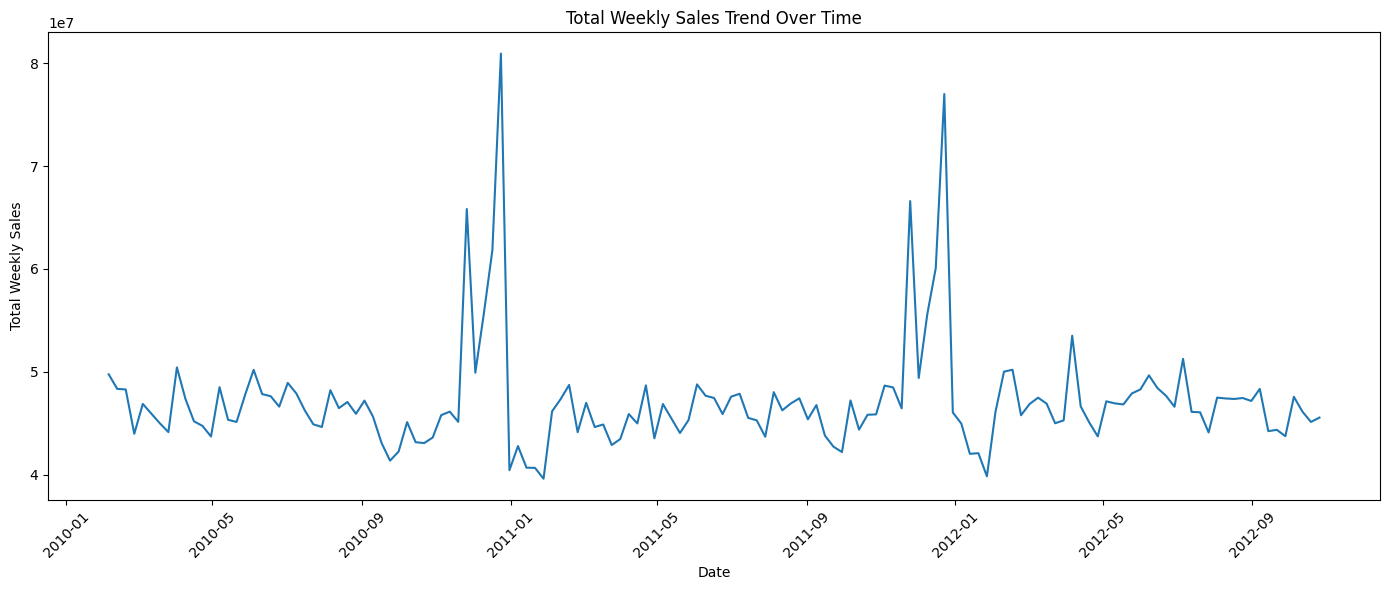

In [15]:
# 4.1 Total Weekly Sales Trend Over Time

# Aggregate weekly sales by date
sales_trend = (
    analysis_df.groupby('Date')['Weekly_Sales']
    .sum()
    .reset_index()
)

# Plot the sales trend
plt.figure(figsize=(14, 6))

plt.plot(
    sales_trend['Date'],
    sales_trend['Weekly_Sales']
)

plt.title('Total Weekly Sales Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Total Weekly Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Business Insight:**

The chart shows how total weekly sales changed over the observed period. Peaks and declines in sales indicate variations in retail demand over time. These patterns are useful for identifying seasonal behavior, unusual sales periods, and potential holiday effects. The observed time-based patterns will be investigated further during anomaly detection and demand forecasting.

##### 1. Why did you pick the specific chart?

This line chart was selected to understand how total weekly sales change over time. It helps identify overall sales patterns, recurring peaks and declines, seasonal variations, and unusual periods. This is particularly relevant to the project because time-based patterns will be used later for anomaly detection and demand forecasting.

##### 2. What is/are the insight(s) found from the chart?

The chart shows substantial variation in total weekly sales over time, with most weeks remaining within a relatively consistent range and a few prominent spikes. The largest sales peaks occur around the end of 2010 and end of 2011, suggesting possible seasonal or holiday-related demand. Noticeable declines also occur after some major peaks. These unusual fluctuations should be investigated further using holiday information and time-based anomaly detection.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can create a positive business impact by helping the business identify high-demand periods and prepare inventory, staffing, and promotional activities accordingly. The recurring sales spikes can also help improve demand forecasting and reduce the risk of stockouts during peak periods.

The sharp declines after some peaks may indicate reduced demand or other influencing factors and could lead to inefficient inventory planning if not investigated. Therefore, understanding the reasons behind these fluctuations can help the business avoid overstocking during low-demand periods and improve overall store performance.

### 4.2 Weekly Sales by Store Type

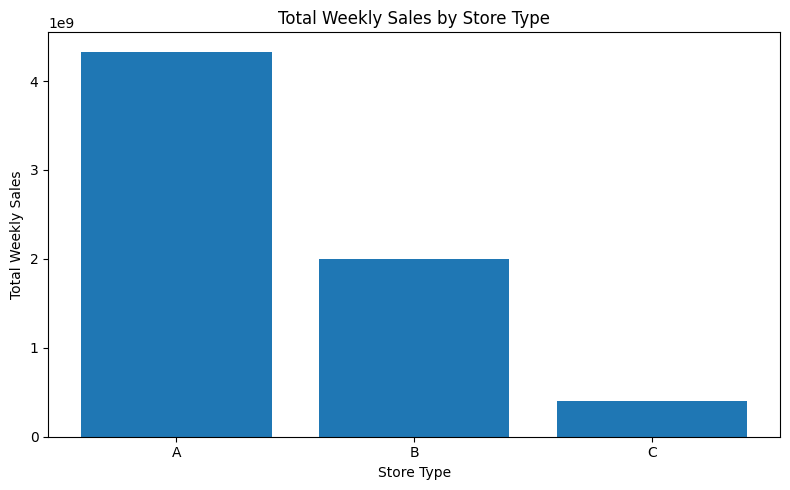

,Type,sum,mean
0,A,4.331015e+09,20099.568043
1,B,2.000701e+09,12237.075977
2,C,4.055035e+08,9519.532538


In [16]:
# 4.2 Weekly Sales by Store Type

# Calculate total and average weekly sales by store type
store_type_sales = (
    analysis_df.groupby('Type')['Weekly_Sales']
    .agg(['sum', 'mean'])
    .reset_index()
)

# Plot total sales by store type
plt.figure(figsize=(8, 5))

plt.bar(
    store_type_sales['Type'],
    store_type_sales['sum']
)

plt.title('Total Weekly Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Total Weekly Sales')
plt.tight_layout()
plt.show()

# Display the summary values
display(store_type_sales)

##### 1. Why did you pick the specific chart?

This chart was selected to compare weekly sales performance across different store types (A, B, and C). It helps identify which store type contributes the most to overall sales and whether store type is associated with differences in sales performance. This analysis is relevant to store segmentation and store optimization.

##### 2. What is/are the insight(s) found from the chart?

Store Type A generates the highest total weekly sales of approximately 4.33 billion, followed by Type B at approximately 2.00 billion and Type C at approximately 0.41 billion.

The average weekly sales are also highest for Type A at approximately 20,100, followed by Type B at approximately 12,237 and Type C at approximately 9,520. This indicates that Type A stores generally have stronger sales performance, while Type C stores have substantially lower sales levels.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can support store optimization by helping management differentiate strategies according to store type. Type A stores may justify higher inventory levels and stronger promotional support because of their higher sales performance, while Type C stores may require more targeted strategies to improve sales.

However, store type alone should not be treated as the cause of higher sales. Store size, location, department mix, holidays, markdowns, and other external factors may also influence sales. These factors should be examined in later analysis before making final business decisions.




### 4.3 Holiday vs Non-Holiday Sales

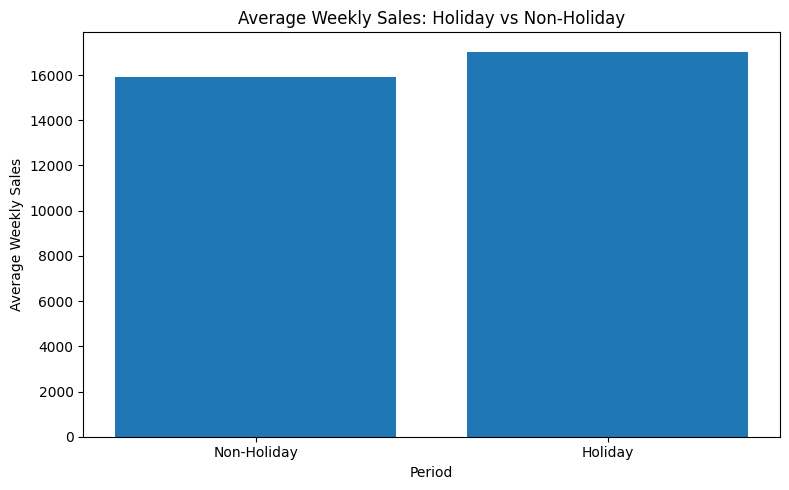

,Holiday_Status,Weekly_Sales
0,Non-Holiday,15901.445069
1,Holiday,17035.823187


In [17]:
# Chart 3: Average Weekly Sales - Holiday vs Non-Holiday

holiday_sales = (
    analysis_df
    .groupby('IsHoliday_sales')['Weekly_Sales']
    .mean()
    .reset_index()
)

holiday_sales['Holiday_Status'] = holiday_sales['IsHoliday_sales'].map({
    False: 'Non-Holiday',
    True: 'Holiday'
})

plt.figure(figsize=(8, 5))

plt.bar(
    holiday_sales['Holiday_Status'],
    holiday_sales['Weekly_Sales']
)

plt.title('Average Weekly Sales: Holiday vs Non-Holiday')
plt.xlabel('Period')
plt.ylabel('Average Weekly Sales')
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

display(
    holiday_sales[['Holiday_Status', 'Weekly_Sales']]
)

##### 1. Why did you pick the specific chart?

This chart was selected to compare average weekly sales during holiday and non-holiday periods. It helps identify whether holidays are associated with changes in sales performance and supports the project's requirement to analyze holiday effects and time-based sales patterns.

##### 2. What is/are the insight(s) found from the chart?

The average weekly sales during holidays are approximately 17,035.82, compared with 15,901.45 during non-holiday periods. This indicates that average weekly sales are about 7.1% higher during holiday periods. Therefore, holidays appear to be associated with increased sales activity in this dataset.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The insight can support positive business impact by helping stores prepare for higher demand during holiday periods. Businesses can plan inventory, staffing, promotions, and product availability in advance. The analysis shows approximately 7.1% higher average weekly sales during holidays, indicating an opportunity to capture additional demand. However, this chart alone does not prove that holidays directly caused the increase, so other factors such as markdowns, seasonality, and external economic conditions should also be considered before making final decisions. No direct evidence of negative growth is identified from this chart.

#### 4.4 Distribution of Weekly Sales

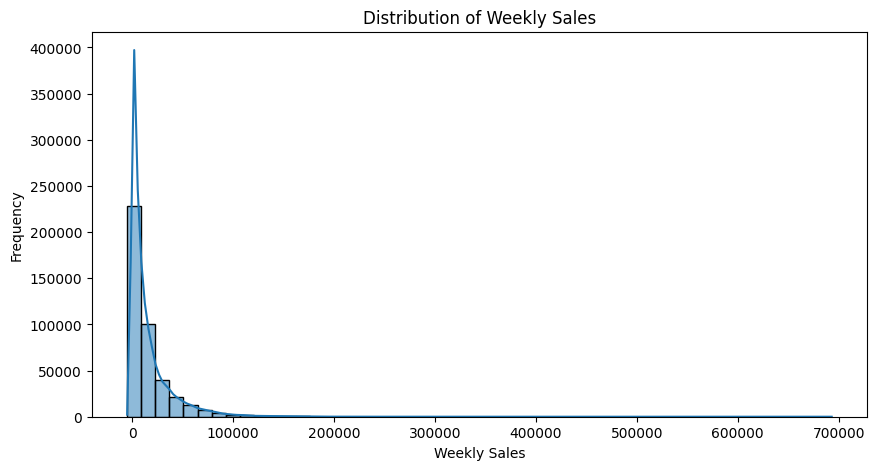

In [18]:
# Chart 4: Distribution of Weekly Sales

plt.figure(figsize=(10, 5))

sns.histplot(
    data=final_df,
    x='Weekly_Sales',
    bins=50,
    kde=True
)

plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales')
plt.ylabel('Frequency')
plt.show()

##### 1. Why did you pick the specific chart?

I selected a histogram with a KDE curve to understand the distribution of Weekly Sales, which is the primary target variable of the project. This chart helps identify the central tendency, spread, skewness, and presence of unusually high or low sales values. Understanding the distribution is important before performing further statistical analysis, anomaly detection, and demand forecasting.

##### 2. What is/are the insight(s) found from the chart?

The Weekly Sales distribution is positively skewed, with most observations concentrated at relatively lower sales values and a smaller number of observations having very high sales. The mean Weekly Sales is approximately 15,981, while the median is approximately 7,612, indicating that high-sales observations increase the mean considerably. The dataset also contains some negative Weekly Sales values and extreme high-sales observations, which should be investigated during outlier and anomaly analysis rather than being automatically removed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The insights can support positive business impact by helping identify normal sales ranges and unusual sales periods. Understanding the skewed distribution is particularly useful for inventory planning, demand forecasting, and anomaly detection. Extremely high sales periods may represent important business opportunities such as holiday demand or successful promotions, while unusually low or negative sales observations should be investigated to determine whether they represent genuine business events or data-related issues. Therefore, the observations should be analyzed carefully before applying any outlier treatment.

#### 4.5 Top 10 Stores by Total Weekly Sales

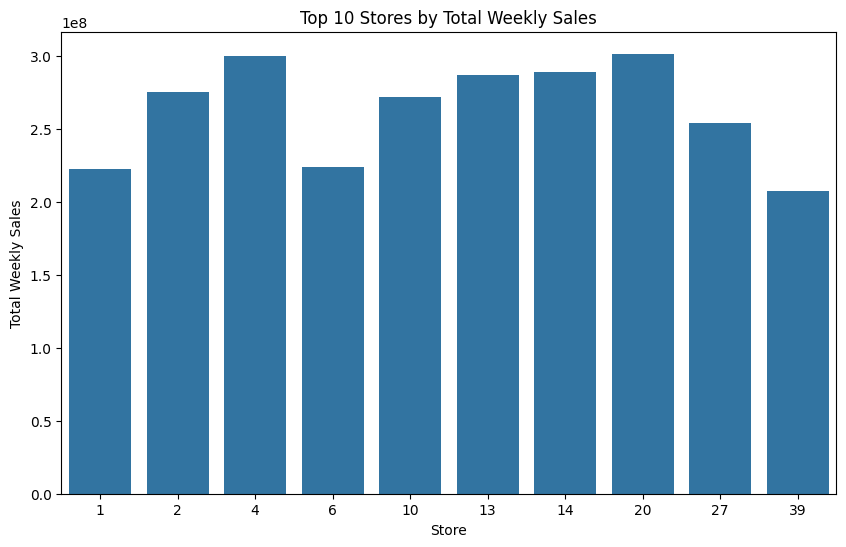

In [19]:
# Chart 5: Top 10 Stores by Total Weekly Sales

top_10_stores = (
    final_df.groupby('Store')['Weekly_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_stores,
    x='Store',
    y='Weekly_Sales'
)

plt.title('Top 10 Stores by Total Weekly Sales')
plt.xlabel('Store')
plt.ylabel('Total Weekly Sales')
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart to compare the total Weekly Sales generated by different stores. A bar chart is appropriate because Store is a categorical variable and the chart allows easy comparison and ranking of store-level sales performance. Identifying the highest and lowest performing stores is important for store optimization and resource allocation.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that total Weekly Sales vary considerably across stores. The top 10 stores contribute substantially to overall sales, indicating differences in store-level performance. These differences may be influenced by factors such as store size, store type, location-related characteristics, promotions, and demand patterns. Further analysis of store characteristics and external factors can help explain these differences.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The insights can create positive business impact by helping management identify high-performing stores and prioritize inventory, staffing, promotions, and other resources according to store-level demand. Lower-performing stores can also be investigated to identify opportunities for improvement. However, the chart only shows total sales and does not by itself explain the reasons for differences in performance, so additional analysis is required before making operational decisions.

#### 4.6 Top 10 Departments by Total Weekly Sales

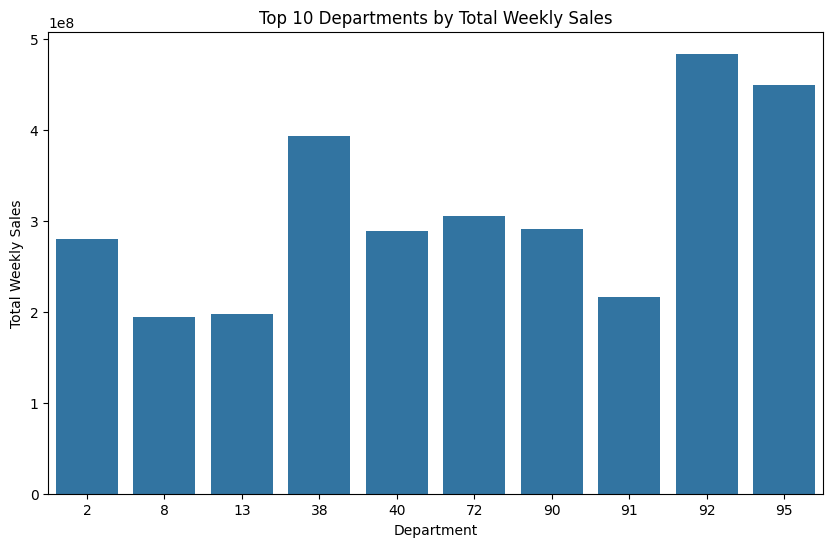

In [20]:
# Chart 6: Top 10 Departments by Total Weekly Sales

top_10_departments = (
    final_df.groupby('Dept')['Weekly_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_departments,
    x='Dept',
    y='Weekly_Sales'
)

plt.title('Top 10 Departments by Total Weekly Sales')
plt.xlabel('Department')
plt.ylabel('Total Weekly Sales')

plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart to compare the total Weekly Sales across departments. Since Department is a categorical variable, a bar chart provides a clear comparison of department-level sales performance. Focusing on the top 10 departments makes the comparison easier to interpret and helps identify departments that contribute substantially to overall sales.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that Weekly Sales contribution varies across departments, with a small group of departments generating substantially higher total sales than others. This indicates that department-level demand is not uniform across the business. The differences can help identify high-demand departments that may require greater attention in inventory planning and sales forecasting.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The insights can support positive business impact by helping management prioritize inventory, replenishment, promotions, and forecasting for high-performing departments. Lower-performing departments can be investigated further to understand their demand patterns and identify improvement opportunities. However, total sales alone does not explain the reasons for the differences, so additional analysis of store, time, holiday, and external factors is required before making business decisions.

#### 4.7 Store Size vs Total Weekly Sales

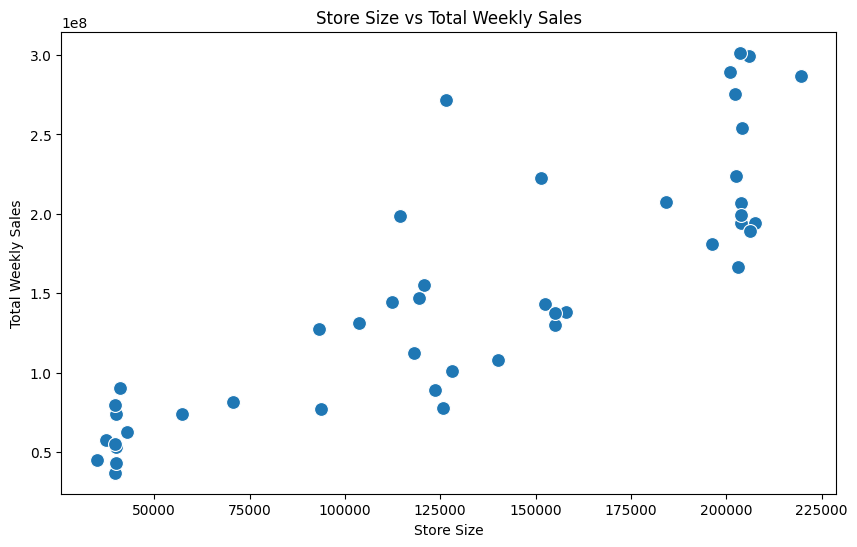

In [21]:
# Chart 7: Store Size vs Total Weekly Sales

store_sales_size = (
    final_df.groupby(['Store', 'Size'])['Weekly_Sales']
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=store_sales_size,
    x='Size',
    y='Weekly_Sales',
    s=100
)

plt.title('Store Size vs Total Weekly Sales')
plt.xlabel('Store Size')
plt.ylabel('Total Weekly Sales')

plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot to examine the relationship between Store Size and Total Weekly Sales. Both variables are numerical, making a scatter plot appropriate for identifying the direction, strength, and pattern of their relationship. This analysis helps determine whether store size may be associated with overall store sales performance.

##### 2. What is/are the insight(s) found from the chart?

The scatter plot shows a generally positive relationship between Store Size and Total Weekly Sales. Larger stores tend to generate higher total sales, while smaller stores generally have lower total sales. However, the relationship is not perfectly linear, as stores with similar sizes can have different sales levels. This indicates that store size is likely an important factor in sales performance, but other factors also influence total sales.The chart shows the relationship between store size and total weekly sales across stores. The observations indicate that stores with larger sizes generally tend to have higher total sales, although the relationship is not perfectly linear and some stores with similar sizes show different sales levels. This suggests that store size may be an important factor in sales performance, while other factors may also influence total sales.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The insight can support positive business impact by helping management understand how store capacity and size relate to sales performance. Store size can be considered when planning inventory levels, staffing, product availability, and store expansion. However, store size alone should not be used to make decisions because sales are also influenced by factors such as store type, department mix, holidays, promotions, and external economic conditions.

#### 4.8 Fuel Price vs Total Weekly Sales

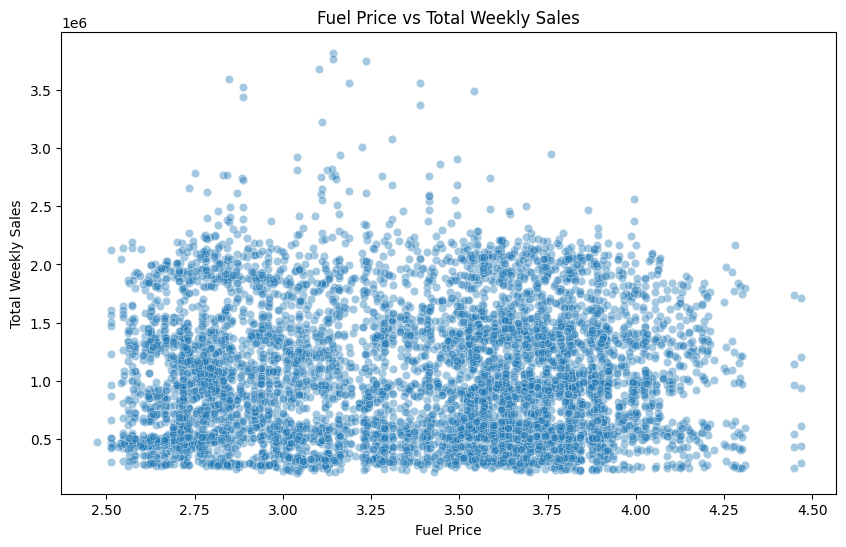

In [22]:
# Chart 8: Fuel Price vs Total Weekly Sales

fuel_sales = (
    final_df.groupby(['Store', 'Date'])[['Fuel_Price', 'Weekly_Sales']]
    .agg({
        'Fuel_Price': 'first',
        'Weekly_Sales': 'sum'
    })
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=fuel_sales,
    x='Fuel_Price',
    y='Weekly_Sales',
    alpha=0.4
)

plt.title('Fuel Price vs Total Weekly Sales')
plt.xlabel('Fuel Price')
plt.ylabel('Total Weekly Sales')

plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot to examine the relationship between Fuel Price and Total Weekly Sales. Both variables are numerical, making a scatter plot suitable for identifying the direction, strength, and overall pattern of their relationship. Fuel Price is an external economic factor that may influence consumer spending and operating conditions, making it relevant to the retail sales analysis.

##### 2. What is/are the insight(s) found from the chart?

The scatter plot shows that Weekly Sales vary considerably across different Fuel Price levels. The observations are widely scattered, and there is no clear strong linear relationship between Fuel Price and Total Weekly Sales. This suggests that Fuel Price alone does not explain the large variation in sales, and other factors such as store characteristics, department, seasonality, holidays, promotions, and economic conditions may also influence sales.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The insight can help create positive business impact by showing that Fuel Price should not be used as the sole factor for making sales or inventory decisions. Instead, it can be considered together with store characteristics, promotions, seasonal patterns, holidays, and other economic indicators when forecasting demand. The absence of a strong visible relationship also helps prevent incorrect business assumptions about the effect of fuel prices on sales.

#### 4.9 CPI vs Total Weekly Sales

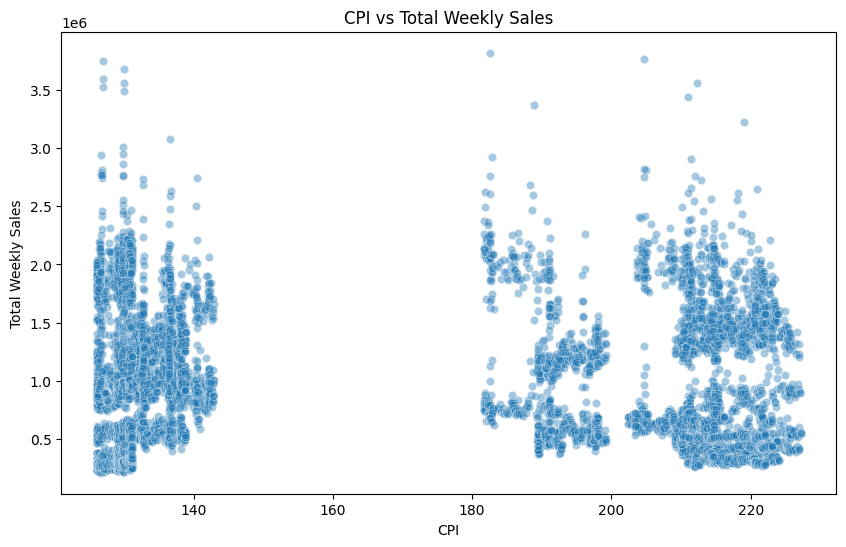

In [23]:
# Chart 9: CPI vs Total Weekly Sales

cpi_sales = (
    final_df.groupby(['Store', 'Date'])[['CPI', 'Weekly_Sales']]
    .agg({
        'CPI': 'first',
        'Weekly_Sales': 'sum'
    })
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cpi_sales,
    x='CPI',
    y='Weekly_Sales',
    alpha=0.4
)

plt.title('CPI vs Total Weekly Sales')
plt.xlabel('CPI')
plt.ylabel('Total Weekly Sales')

plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot to examine the relationship between CPI and Total Weekly Sales. Both variables are numerical, making a scatter plot suitable for identifying the direction, strength, and overall pattern of their relationship. CPI is an important economic indicator and can help assess whether changes in the economic environment are associated with changes in retail sales.

##### 2. What is/are the insight(s) found from the chart?

The scatter plot shows substantial variation in Weekly Sales across the observed CPI levels. The observations are distributed across several CPI ranges, and there is no clear strong linear relationship between CPI and Total Weekly Sales. This suggests that CPI alone does not explain the large variation in sales, and other factors such as store characteristics, department, seasonality, holidays, promotions, and other economic conditions may also influence sales.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.


The insight can support positive business impact by showing that CPI should not be considered as the sole factor when making sales, inventory, or forecasting decisions. CPI can instead be considered together with other store, promotional, seasonal, and economic variables when predicting demand. This helps avoid making business decisions based on a single economic indicator.

#### 4.10 Unemployment vs Total Weekly Sales

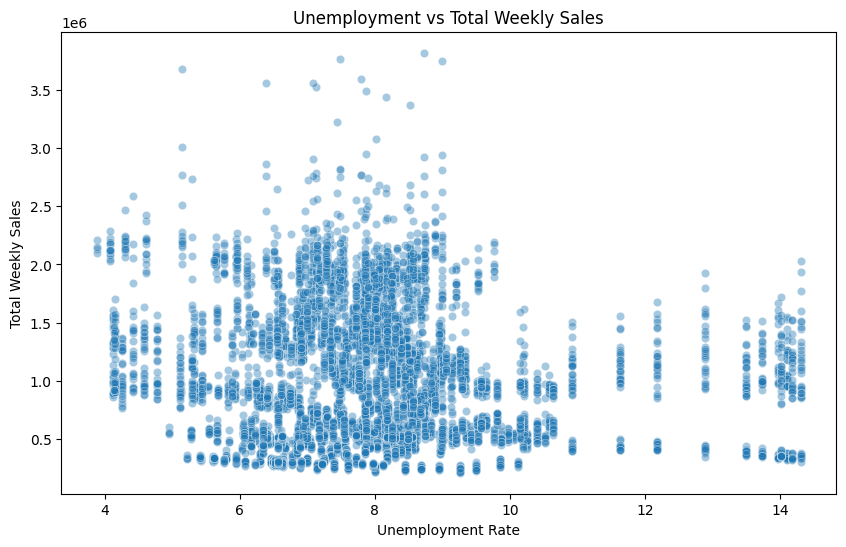

In [24]:
# Chart 10: Unemployment vs Total Weekly Sales

unemployment_sales = (
    final_df.groupby(['Store', 'Date'])[['Unemployment', 'Weekly_Sales']]
    .agg({
        'Unemployment': 'first',
        'Weekly_Sales': 'sum'
    })
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=unemployment_sales,
    x='Unemployment',
    y='Weekly_Sales',
    alpha=0.4
)

plt.title('Unemployment vs Total Weekly Sales')
plt.xlabel('Unemployment Rate')
plt.ylabel('Total Weekly Sales')

plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot to examine the relationship between Unemployment and Total Weekly Sales. Both variables are numerical, making a scatter plot appropriate for identifying the direction, strength, and overall pattern of their relationship. Unemployment is an important economic indicator that can help assess whether changes in employment conditions are associated with changes in retail sales.

##### 2. What is/are the insight(s) found from the chart?

The scatter plot shows substantial variation in Weekly Sales across different unemployment-rate levels. The observations are widely scattered, and there is no clear strong linear relationship between Unemployment and Total Weekly Sales. This indicates that unemployment alone does not explain the large variation in sales, and other factors such as store characteristics, department, seasonality, holidays, promotions, and other economic conditions may also influence sales.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The insight can support positive business impact by showing that unemployment should not be used as the sole factor for sales or inventory decisions. It can instead be considered together with store characteristics, promotional activity, seasonal patterns, holidays, and other economic indicators when forecasting demand. This helps management make more informed decisions using multiple relevant factors rather than relying on a single economic indicator.

#### 4.11 Total Markdown vs Total Weekly Sales

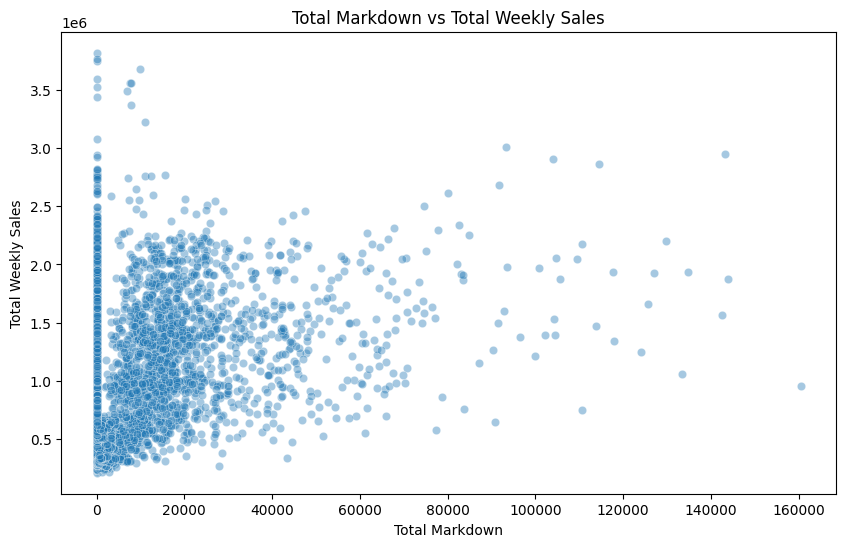

In [25]:
# Chart 11: Total Markdown vs Total Weekly Sales

markdown_sales = final_df.copy()

# Calculate total markdown across all five markdown columns
markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']

markdown_sales['Total_Markdown'] = markdown_sales[markdown_cols].sum(axis=1)

# Aggregate to Store-Date level
markdown_sales = (
    markdown_sales.groupby(['Store', 'Date'])[['Total_Markdown', 'Weekly_Sales']]
    .agg({
        'Total_Markdown': 'first',
        'Weekly_Sales': 'sum'
    })
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=markdown_sales,
    x='Total_Markdown',
    y='Weekly_Sales',
    alpha=0.4
)

plt.title('Total Markdown vs Total Weekly Sales')
plt.xlabel('Total Markdown')
plt.ylabel('Total Weekly Sales')

plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot to examine the relationship between Total Markdown and Total Weekly Sales. Both variables are numerical, making a scatter plot suitable for identifying the direction, strength, and overall pattern of their relationship. Markdown represents promotional activity, making this analysis relevant for understanding whether promotional intensity is associated with retail sales.

##### 2. What is/are the insight(s) found from the chart?

The scatter plot shows that Weekly Sales vary substantially across different levels of Total Markdown. Most observations are concentrated at lower markdown values, while higher markdown values are associated with a wide range of sales levels. The pattern suggests that promotional activity may be associated with higher sales in some cases, but the relationship is not strong or consistent enough to conclude that markdowns alone determine sales. Other factors such as store, department, seasonality, holidays, and economic conditions may also influence sales.

**Assumption and limitation:** missing markdown entries were filled with zero as a proxy for no recorded markdown activity. This is a practical assumption, not proof that no markdown occurred; verify against source-system definitions if available.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The insight can support positive business impact by helping management evaluate the role of promotional markdowns in driving sales. Markdown strategies can be considered together with demand patterns, store characteristics, holidays, and seasonal factors when planning promotions and inventory. However, markdowns should not be increased solely to generate sales because the chart does not establish a causal relationship, and excessive discounting could reduce profitability.

#### 4.12 Average Weekly Sales by Month

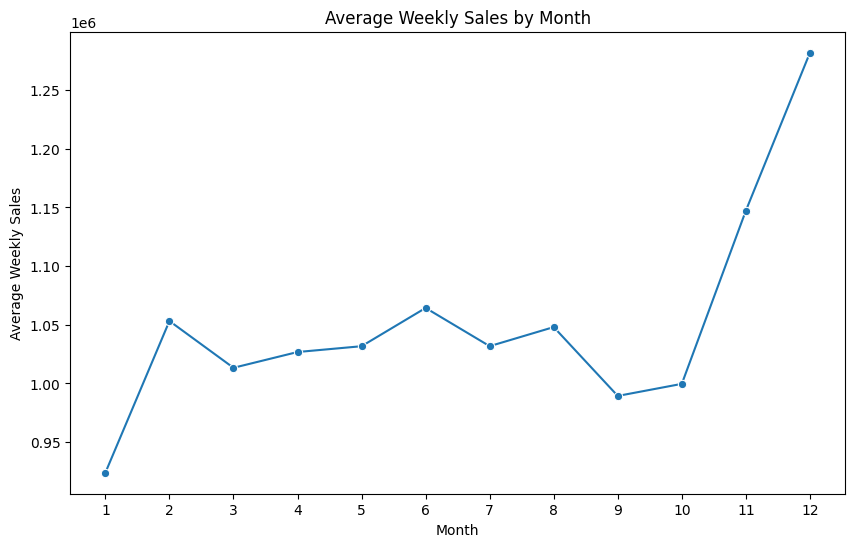

In [26]:
# Chart 12: Average Weekly Sales by Month

monthly_sales = final_df.copy()

# Extract month from Date
monthly_sales['Month'] = monthly_sales['Date'].dt.month

# Calculate total weekly sales for each store and date
monthly_sales = (
    monthly_sales.groupby(['Store', 'Date', 'Month'])['Weekly_Sales']
    .sum()
    .reset_index()
)

# Calculate average weekly sales for each month
monthly_avg_sales = (
    monthly_sales.groupby('Month')['Weekly_Sales']
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=monthly_avg_sales,
    x='Month',
    y='Weekly_Sales',
    marker='o'
)

plt.title('Average Weekly Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Weekly Sales')

plt.xticks(range(1, 13))

plt.show()

##### 1. Why did you pick the specific chart?

I selected a line chart to analyze the monthly pattern of average Weekly Sales. Month is an ordered time-based variable, making a line chart appropriate for identifying seasonal patterns, recurring increases or decreases in demand, and periods of higher or lower sales. Understanding seasonality is important for inventory planning and demand forecasting.

##### 2. What is/are the insight(s) found from the chart?

The chart shows noticeable variation in average Weekly Sales across the months. January has the lowest average sales, followed by an increase in February. Sales fluctuate moderately through the middle of the year, with relatively lower sales in September. Sales increase again during October and November, while December records the highest average Weekly Sales. This indicates the presence of a seasonal pattern in retail demand, particularly toward the end of the year.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The seasonal pattern can create positive business impact by helping management prepare inventory, staffing, promotions, and store capacity according to expected demand. The higher sales observed toward November and December indicate that sufficient inventory and resources may be required during this period, while lower-demand periods can be managed with more controlled inventory levels. These seasonal patterns can also improve the accuracy of future demand forecasting.

#### 4.13 Average Weekly Sales by Store Type and Holiday Status

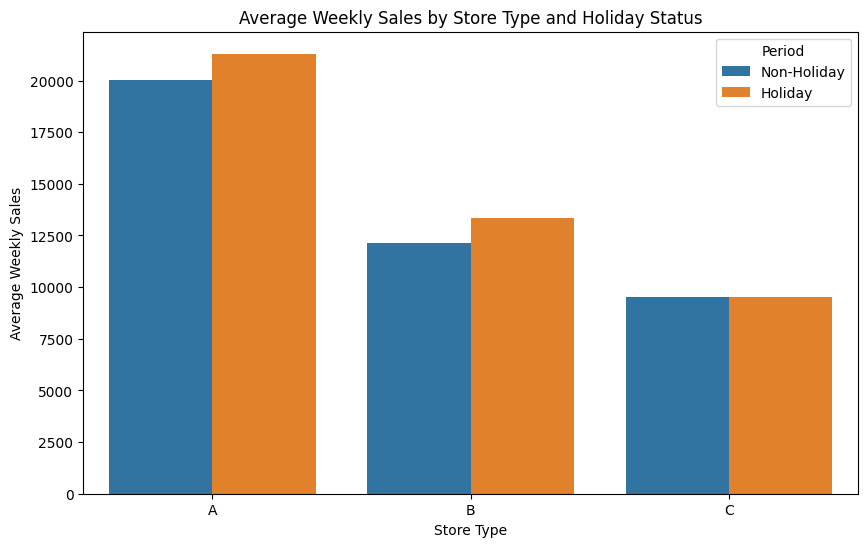

In [27]:
 # Chart 13: Average Weekly Sales by Store Type and Holiday Status

store_holiday_sales = (
    final_df.groupby(['Type', 'IsHoliday_sales'])['Weekly_Sales']
    .mean()
    .reset_index()
)

# Create readable holiday labels
store_holiday_sales['Holiday_Status'] = store_holiday_sales['IsHoliday_sales'].map({
    False: 'Non-Holiday',
    True: 'Holiday'
})

plt.figure(figsize=(10, 6))

sns.barplot(
    data=store_holiday_sales,
    x='Type',
    y='Weekly_Sales',
    hue='Holiday_Status'
)

plt.title('Average Weekly Sales by Store Type and Holiday Status')
plt.xlabel('Store Type')
plt.ylabel('Average Weekly Sales')
plt.legend(title='Period')

plt.show()

##### 1. Why did you pick the specific chart?

I selected a grouped bar chart to compare average Weekly Sales across different Store Types during holiday and non-holiday periods. This chart combines store type and holiday status, allowing us to examine whether holiday-related changes in sales differ across store types. The analysis is useful for understanding store-specific demand patterns and supporting holiday planning.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that Store Types A and B have noticeably higher average Weekly Sales during holidays compared with non-holiday periods. For Store Type C, the difference between holiday and non-holiday sales is much smaller. Store Type A has the highest average sales overall, followed by Type B and Type C. This indicates that the impact of holiday periods varies across store types.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

These insights can support positive business impact by helping management plan inventory, staffing, promotions, and resources differently for each store type during holiday periods. Store Types A and B may require greater preparation for increased holiday demand, while Type C may require less adjustment. Store-specific planning can help reduce stockouts during high-demand periods and avoid unnecessary excess inventory.

#### 4.14 Correlation Heatmap of Numerical Variables

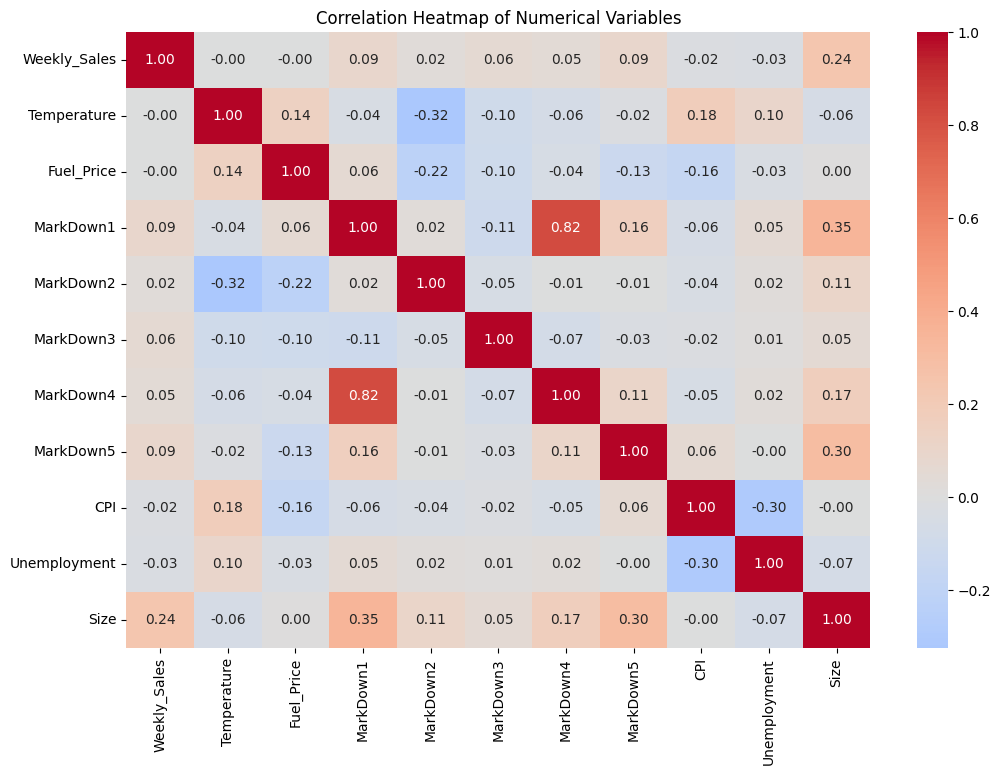

In [28]:
# Chart 14: Correlation Heatmap

# Select important numerical variables
correlation_columns = [
    'Weekly_Sales',
    'Temperature',
    'Fuel_Price',
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5',
    'CPI',
    'Unemployment',
    'Size'
]

correlation_matrix = final_df[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

##### 1. Why did you pick the specific chart?

I selected a correlation heatmap to examine the strength and direction of relationships among the important numerical variables in the dataset. The heatmap provides a compact visual representation of correlations between Weekly Sales, store characteristics, promotional markdowns, and external economic factors. This analysis helps identify potentially related variables and provides useful guidance for subsequent feature engineering and ML modeling.

##### 2. What is/are the insight(s) found from the chart?

The heatmap shows that Store Size has the strongest positive correlation with Weekly Sales among the selected variables, with a correlation of approximately 0.24, indicating a weak positive linear relationship. The correlations between Weekly Sales and the individual markdown and economic variables are generally weak. A strong positive correlation of approximately 0.82 is observed between MarkDown1 and MarkDown4, while CPI and Unemployment show a negative correlation of approximately -0.30. These relationships provide useful information for feature engineering and further analysis, but correlation does not establish causation.

#### 4.15 - Pair Plot

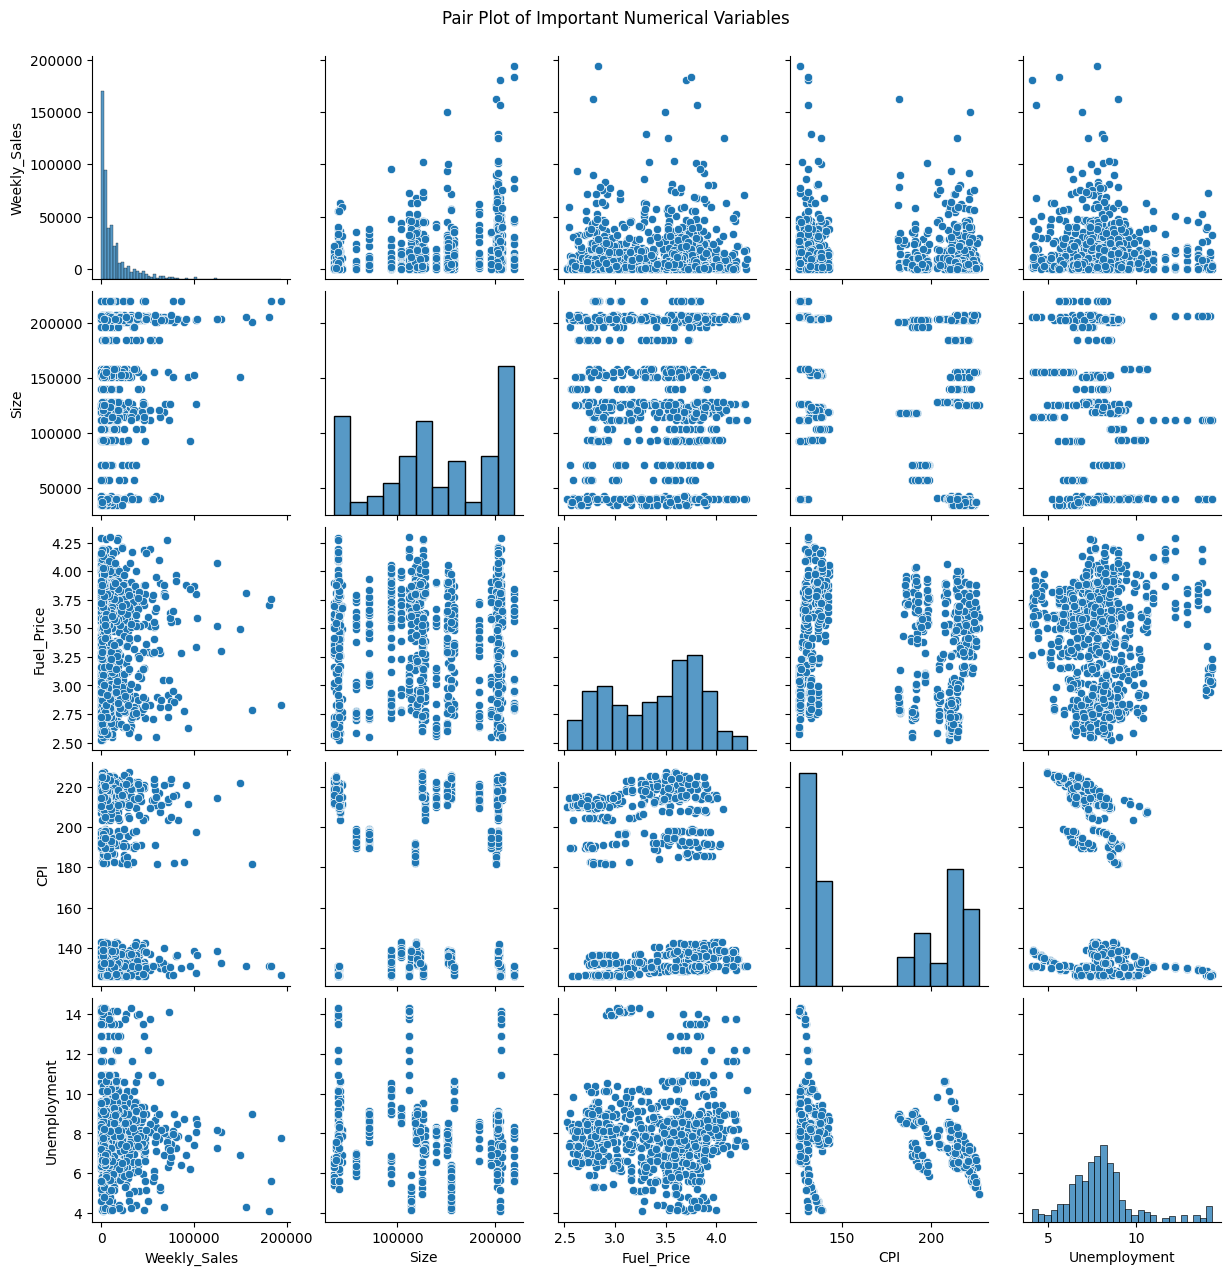

In [29]:
# Chart 15: Pair Plot

# Select important numerical variables for pairwise analysis
pairplot_columns = [
    'Weekly_Sales',
    'Size',
    'Fuel_Price',
    'CPI',
    'Unemployment'
]

# Take a sample to make the pair plot efficient and readable
pairplot_data = final_df[pairplot_columns].dropna().sample(
    n=1000,
    random_state=42
)

sns.pairplot(
    pairplot_data,
    diag_kind='hist'
)

plt.suptitle(
    'Pair Plot of Important Numerical Variables',
    y=1.02
)

plt.show()

##### 1. Why did you pick the specific chart?

I selected a pair plot to examine the pairwise relationships and distributions of important numerical variables simultaneously. It helps identify potential relationships, patterns, clusters, and distributions among Weekly Sales, Store Size, Fuel Price, CPI, and Unemployment. This provides a broader understanding of the numerical variables before proceeding to statistical testing and machine learning.

##### 2. What is/are the insight(s) found from the chart?

The pair plot shows that Weekly Sales have a highly right-skewed distribution, with most observations concentrated at lower sales values and a smaller number of high-sales observations. The relationship between Weekly Sales and Store Size shows some positive association, which is consistent with the correlation analysis. Fuel Price and Weekly Sales do not show a clear strong relationship. CPI and Unemployment show a noticeable negative relationship, while their individual relationships with Weekly Sales appear relatively weak. Overall, the pair plot confirms that multiple factors may influence sales and that no single external variable clearly explains Weekly Sales.

## Required rubric component: Anomaly Detection in Weekly Sales

**Purpose:** flag unusual weekly sales observations for review, while retaining genuine high-demand observations in the forecasting data. This is an investigation aid, not a claim that every flagged point is an error. The code uses a robust within-store/department baseline and median absolute deviation (MAD), which helps account for different normal sales levels across departments. It reports flagged rows and checks their dates/holiday status. Review flagged events with business context before taking action.

In [30]:
# Robust within-store/department anomaly screening (MAD-based)
# Requires analysis_df from the data-wrangling section.
import numpy as np
import pandas as pd

required_cols = {'Store', 'Dept', 'Date', 'Weekly_Sales'}
missing_cols = required_cols - set(analysis_df.columns)
if missing_cols:
    raise ValueError(f"analysis_df is missing required columns: {sorted(missing_cols)}")

anomaly_df = analysis_df.copy()
anomaly_df['Date'] = pd.to_datetime(anomaly_df['Date'])
anomaly_df = anomaly_df.sort_values(['Store', 'Dept', 'Date'])

def robust_mad_flags(series, threshold=3.5):
    median = series.median()
    mad = (series - median).abs().median()
    if pd.isna(mad) or mad == 0:
        # If MAD is zero, use a conservative IQR fallback for this group.
        q1, q3 = series.quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr == 0:
            return pd.Series(False, index=series.index)
        return (series < q1 - 3 * iqr) | (series > q3 + 3 * iqr)
    modified_z = 0.6745 * (series - median) / mad
    return modified_z.abs() > threshold

anomaly_df['Is_Sales_Anomaly'] = (
    anomaly_df.groupby(['Store', 'Dept'])['Weekly_Sales']
    .transform(lambda s: robust_mad_flags(s).astype(bool))
)
flagged_anomalies = anomaly_df[anomaly_df['Is_Sales_Anomaly']].copy()
print('Rows reviewed:', len(anomaly_df))
print('Potential anomalies flagged:', len(flagged_anomalies))
print('Percentage flagged:', round(100 * len(flagged_anomalies) / max(len(anomaly_df), 1), 2), '%')
print('Potential anomalies by year:')
display(flagged_anomalies.assign(Year=flagged_anomalies['Date'].dt.year).groupby('Year').size().rename('Flagged_Count').to_frame())
cols_to_show = [c for c in ['Store','Dept','Date','Weekly_Sales','IsHoliday_sales','IsHoliday_features','MarkDown1','MarkDown2','MarkDown3','MarkDown4','MarkDown5'] if c in flagged_anomalies.columns]
display(flagged_anomalies[cols_to_show].sort_values('Weekly_Sales', ascending=False).head(15))
print('Interpretation: flags identify observations for review; they are not automatically removed or labelled as errors.')

Rows reviewed: 421570
Potential anomalies flagged: 15999
Percentage flagged: 3.8 %
Potential anomalies by year:


,Flagged_Count
Year,
2010,6969
2011,6263
2012,2767


,Store,Dept,Date,Weekly_Sales,IsHoliday_sales,IsHoliday_features,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
95373,10,72,2010-11-26,693099.36,True,True,0.00,0.00,0.00,0.00,0.00
338013,35,72,2011-11-25,649770.18,True,True,1333.24,0.00,58563.24,20.97,6386.86
95425,10,72,2011-11-25,630999.19,True,True,174.72,329.00,141630.61,79.00,1009.98
337961,35,72,2010-11-26,627962.93,True,True,0.00,0.00,0.00,0.00,0.00
135665,14,72,2010-11-26,474330.10,True,True,0.00,0.00,0.00,0.00,0.00
195088,20,72,2010-11-26,422306.25,True,True,0.00,0.00,0.00,0.00,0.00
264390,27,72,2010-11-26,420586.57,True,True,0.00,0.00,0.00,0.00,0.00
88428,10,7,2010-12-24,406988.63,False,False,0.00,0.00,0.00,0.00,0.00
95377,10,72,2010-12-24,404245.03,False,False,0.00,0.00,0.00,0.00,0.00
214432,22,72,2010-11-26,393705.20,True,True,0.00,0.00,0.00,0.00,0.00


Interpretation: flags identify observations for review; they are not automatically removed or labelled as errors.


### Anomaly detection — interpretation and business use

Potential anomalies are identified relative to each Store–Department sales history, rather than by applying one sales threshold to every department. This is important because departments differ greatly in their normal sales levels. Flagged weeks should be checked against holiday timing, markdown activity, data quality, and known store events. The method does not establish the cause of an unusual observation, and genuine demand spikes should not be deleted automatically. A production version should validate thresholds with business owners and monitor false positives/false negatives.

## Required rubric component: Store Segmentation

**Scope limitation:** the supplied data has store attributes and sales, but no customer-level records. This is therefore **store segmentation**, not customer segmentation. The following analysis aggregates store performance and uses K-Means clustering. Numeric features are standardized before clustering; silhouette score is used to compare a small set of cluster counts. Results describe similarity in the selected measures and do not imply causal store categories.

In [31]:
# Store-level segmentation using sales and store characteristics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

store_agg = analysis_df.groupby('Store').agg(
    Mean_Weekly_Sales=('Weekly_Sales', 'mean'),
    Median_Weekly_Sales=('Weekly_Sales', 'median'),
    Sales_Std=('Weekly_Sales', 'std'),
    Total_Weekly_Sales=('Weekly_Sales', 'sum'),
    Mean_Markdown=('MarkDown1', 'mean'),
    Mean_Temperature=('Temperature', 'mean'),
    Mean_Fuel_Price=('Fuel_Price', 'mean'),
    Mean_CPI=('CPI', 'mean'),
    Mean_Unemployment=('Unemployment', 'mean'),
    Size=('Size', 'first')
).reset_index()
if 'Type' in analysis_df.columns:
    store_type = analysis_df.groupby('Store')['Type'].first().rename('Type')
    store_agg = store_agg.merge(store_type, on='Store', how='left')

segment_features = [
    'Mean_Weekly_Sales', 'Median_Weekly_Sales', 'Sales_Std',
    'Mean_Markdown', 'Mean_Temperature', 'Mean_Fuel_Price',
    'Mean_CPI', 'Mean_Unemployment', 'Size'
]
segment_matrix = store_agg[segment_features].replace([np.inf, -np.inf], np.nan)
segment_matrix = segment_matrix.fillna(segment_matrix.median())
segment_scaled = StandardScaler().fit_transform(segment_matrix)

# Compare candidate cluster counts and select the best silhouette score.
cluster_scores = []
for k in range(2, min(6, len(store_agg) - 1) + 1):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(segment_scaled)
    score = silhouette_score(segment_scaled, labels)
    cluster_scores.append({'k': k, 'silhouette_score': score})
score_df = pd.DataFrame(cluster_scores).sort_values('silhouette_score', ascending=False)
display(score_df)
best_k = int(score_df.iloc[0]['k'])
final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
store_agg['Store_Segment'] = final_kmeans.fit_predict(segment_scaled)
print('Selected number of clusters:', best_k)
print('Silhouette score:', round(float(score_df.iloc[0]['silhouette_score']), 4))
print('Store counts by segment:')
display(store_agg['Store_Segment'].value_counts().sort_index().rename('Store_Count').to_frame())
print('Segment profile (sales values are weekly averages unless labelled total):')
display(store_agg.groupby('Store_Segment')[['Mean_Weekly_Sales','Median_Weekly_Sales','Sales_Std','Size','Mean_Markdown']].mean().round(2))
if 'Type' in store_agg.columns:
    print('Store type distribution by segment:')
    display(pd.crosstab(store_agg['Store_Segment'], store_agg['Type']))

,k,silhouette_score
4,6,0.333036
3,5,0.299278
0,2,0.286067
2,4,0.278580
1,3,0.259660


Selected number of clusters: 6
Silhouette score: 0.333
Store counts by segment:


,Store_Count
Store_Segment,
0,10
1,13
2,9
3,2
4,3
5,8


Segment profile (sales values are weekly averages unless labelled total):


,Mean_Weekly_Sales,Median_Weekly_Sales,Sales_Std,Size,Mean_Markdown
Store_Segment,,,,,
0,18922.54,10049.03,22896.52,184605.80,3092.10
1,12829.21,7070.32,15788.85,119364.46,2642.55
2,8351.40,2326.01,13370.35,51008.56,601.10
3,16791.10,9541.78,20203.65,159270.00,3839.07
4,8221.42,985.96,13321.86,39690.00,133.09
5,25662.50,13887.96,31309.37,196057.38,3878.10


Store type distribution by segment:


Type,A,B,C
Store_Segment,,,
0,9,1,0
1,3,10,0
2,1,4,4
3,1,1,0
4,1,0,2
5,7,1,0


### Store segmentation — interpretation and business use

The K-Means model groups stores with similar standardized sales patterns, store sizes, markdown levels, and selected external factors. The silhouette score measures how well-separated the resulting clusters are (higher is generally better, with values near 1 indicating stronger separation). Use the computed cluster profiles to describe each segment based on its actual values; do not assign names such as “high-performing” unless the profile supports that interpretation. Segment-level differences can guide differentiated inventory, staffing, and promotional review. This is store segmentation only; customer segmentation is not possible with the supplied fields.

## Required rubric component: Market Basket Analysis — Data Limitation and Proxy

The supplied files do not contain transaction IDs, customer IDs, product IDs, or item-level baskets. Therefore, transaction-based market basket rules such as support, confidence, and lift cannot be computed honestly. As a transparent alternative, the following code explores **department-level weekly sales co-movement**. Departments with correlated sales may warrant further investigation, but correlation is not proof that customers buy the departments together and must not be presented as genuine market basket analysis.

Top positively correlated department pairs (exploratory proxy):


,Department_1,Department_2,Correlation
0,24,33,0.981
1,5,55,0.943
2,90,92,0.938
3,7,23,0.936
4,14,55,0.934
5,5,14,0.930
6,29,32,0.927
7,7,14,0.926
8,14,22,0.912
9,17,22,0.911


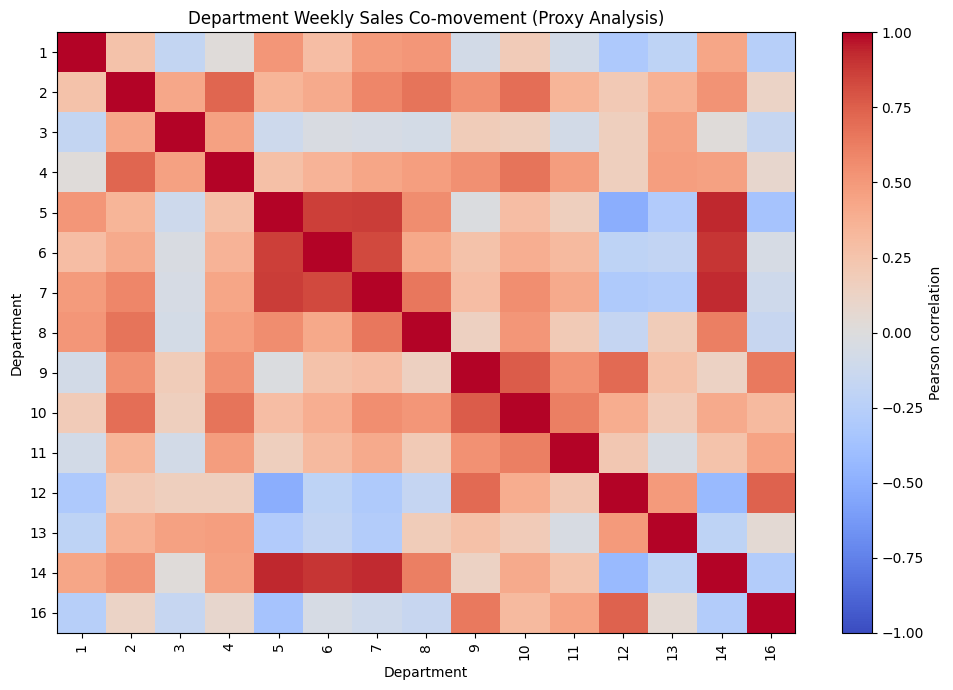

Limitation: these correlations do not measure item-level co-purchases, support, confidence, or lift.


In [32]:
# Department-level sales co-movement proxy (NOT transaction-based market basket analysis)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Aggregate weekly sales by date and department across stores.
dept_weekly = (analysis_df.groupby(['Date', 'Dept'])['Weekly_Sales']
               .sum().reset_index())
dept_pivot = dept_weekly.pivot(index='Date', columns='Dept', values='Weekly_Sales')
# Keep departments with sufficient observed weekly data.
minimum_observations = max(10, int(0.5 * len(dept_pivot)))
valid_depts = dept_pivot.columns[dept_pivot.notna().sum() >= minimum_observations]
dept_pivot = dept_pivot[valid_depts]
dept_corr = dept_pivot.corr(min_periods=minimum_observations)

# List the strongest positive pairs without duplicate/reversed pairs or self-pairs.
pairs = []
cols = list(dept_corr.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        corr_value = dept_corr.iloc[i, j]
        if pd.notna(corr_value):
            pairs.append({'Department_1': cols[i], 'Department_2': cols[j], 'Correlation': corr_value})
pair_df = pd.DataFrame(pairs)
if pair_df.empty:
    print('Not enough overlapping weekly observations to calculate department co-movement reliably.')
else:
    pair_df['Absolute_Correlation'] = pair_df['Correlation'].abs()
    top_pairs = pair_df.sort_values('Correlation', ascending=False).head(10)
    print('Top positively correlated department pairs (exploratory proxy):')
    display(top_pairs[['Department_1','Department_2','Correlation']].reset_index(drop=True).round(3))
    # Plot a compact heatmap for up to 15 departments with the most complete data.
    chosen = list(dept_pivot.notna().sum().sort_values(ascending=False).head(15).index)
    corr_small = dept_pivot[chosen].corr(min_periods=minimum_observations)
    plt.figure(figsize=(10, 7))
    plt.imshow(corr_small, aspect='auto', vmin=-1, vmax=1, cmap='coolwarm')
    plt.colorbar(label='Pearson correlation')
    plt.xticks(range(len(chosen)), chosen, rotation=90)
    plt.yticks(range(len(chosen)), chosen)
    plt.title('Department Weekly Sales Co-movement (Proxy Analysis)')
    plt.xlabel('Department')
    plt.ylabel('Department')
    plt.tight_layout()
    plt.show()
print('Limitation: these correlations do not measure item-level co-purchases, support, confidence, or lift.')

### Market basket proxy — interpretation and business use

Use the computed department pairs as hypotheses for further investigation, not as confirmed cross-selling rules. Positive correlation means the departments' aggregated weekly sales tended to rise and fall together during the observed period; common seasonality, holidays, store coverage, or promotions could explain the relationship. Genuine market basket analysis requires transaction-level item data. A future extension should use transaction ID, product/item ID, and ideally customer or basket information to calculate support, confidence, and lift.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the chart experiments, the following three hypothetical statements are proposed for statistical testing:
1. Holiday periods have a different average Weekly Sales compared with non-holiday periods.
2. Store Size is significantly associated with Weekly Sales.
3. Average Weekly Sales differ significantly across Store Types.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis (H₀): There is no significant difference in average Weekly Sales between holiday and non-holiday periods.

Alternate Hypothesis (H₁): There is a significant difference in average Weekly Sales between holiday and non-holiday periods.

#### 2. Perform an appropriate statistical test.

In [33]:
# Hypothesis 1: Paired comparison of holiday and non-holiday sales by store
# Each store is one paired unit, reducing the risk of treating every store-week as independent.
from scipy.stats import ttest_rel

store_holiday_means = (
    final_df.groupby(['Store', 'IsHoliday_sales'])['Weekly_Sales']
    .mean()
    .unstack('IsHoliday_sales')
    .rename(columns={False: 'NonHoliday_Mean', True: 'Holiday_Mean'})
    .dropna(subset=['NonHoliday_Mean', 'Holiday_Mean'])
)

# Paired t-test: compare each store's mean sales during holiday vs non-holiday weeks.
t_stat, p_value = ttest_rel(
    store_holiday_means['Holiday_Mean'],
    store_holiday_means['NonHoliday_Mean']
)

print("Stores included in paired test:", len(store_holiday_means))
print("Mean store-level sales during holiday weeks:", store_holiday_means['Holiday_Mean'].mean())
print("Mean store-level sales during non-holiday weeks:", store_holiday_means['NonHoliday_Mean'].mean())
print("Paired t-statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05
if p_value < alpha:
    print("\nDecision: Reject the Null Hypothesis.")
    print("There is evidence of a difference in store-level average sales between holiday and non-holiday weeks.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis.")
    print("The test does not provide sufficient evidence of a difference in store-level average sales.")
print("Interpretation: this is an association, not proof that holidays cause the difference.")

Stores included in paired test: 45
Mean store-level sales during holiday weeks: 16420.02996599496
Mean store-level sales during non-holiday weeks: 15363.684091286754
Paired t-statistic: 9.697006805822516
P-value: 1.7107659647529022e-12

Decision: Reject the Null Hypothesis.
There is evidence of a difference in store-level average sales between holiday and non-holiday weeks.
Interpretation: this is an association, not proof that holidays cause the difference.


##### Which statistical test have you done to obtain P-Value?

A paired t-test was performed on each store’s mean sales during holiday weeks versus non-holiday weeks to obtain the P-value.

##### Why did you choose the specific statistical test?

A paired t-test was chosen because the same stores contribute both a holiday-week mean and a non-holiday-week mean. Pairing by store controls for some persistent differences in store sales levels. A significance level of 0.05 was used. The test remains exploratory and does not prove that holidays cause sales changes.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis (H₀): There is no significant association between Store Size and total Weekly Sales across stores.

Alternate Hypothesis (H₁): There is a significant association between Store Size and total Weekly Sales across stores.

#### 2. Perform an appropriate statistical test.

In [34]:
# Hypothesis 2: Store Size vs Total Weekly Sales

from scipy.stats import pearsonr

# Calculate total sales for each store
store_sales = (
    final_df.groupby('Store')['Weekly_Sales']
    .sum()
    .reset_index(name='Total_Weekly_Sales')
)

# Get store size information
store_size = final_df[['Store', 'Size']].drop_duplicates()

# Combine store sales and store size
store_level_data = pd.merge(
    store_sales,
    store_size,
    on='Store',
    how='inner'
)

# Perform Pearson correlation test
correlation, p_value = pearsonr(
    store_level_data['Size'],
    store_level_data['Total_Weekly_Sales']
)

print("Pearson Correlation:", correlation)
print("P-value:", p_value)

# Decision using 5% significance level
alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the Null Hypothesis.")
    print("Conclusion: There is a statistically significant association between Store Size and total Weekly Sales.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis.")
    print("Conclusion: There is no statistically significant association between Store Size and total Weekly Sales.")

Pearson Correlation: 0.8461612451718924
P-value: 2.501425419392169e-13

Decision: Reject the Null Hypothesis.
Conclusion: There is a statistically significant association between Store Size and total Weekly Sales.


##### Which statistical test have you done to obtain P-Value?

Pearson Correlation Test (Pearson's r) was used to obtain the P-value.

##### Why did you choose the specific statistical test?

The Pearson correlation test was chosen because both Store Size and total Weekly Sales are continuous numerical variables. The test measures the strength and direction of their linear association and provides a P-value to determine whether the observed relationship is statistically significant.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis (H₀): There is no statistically significant difference in average Weekly Sales among Store Types A, B, and C.

Alternative Hypothesis (H₁): There is a statistically significant difference in average Weekly Sales among at least one of the Store Types A, B, or C.

#### 2. Perform an appropriate statistical test.

In [35]:
# Hypothesis 3: Compare store-level average weekly sales across store types
# Aggregate to one observation per store to avoid treating repeated store-week rows as independent.
from scipy.stats import f_oneway

store_type_means = (
    final_df.groupby(['Store', 'Type'], as_index=False)['Weekly_Sales']
    .mean()
)
type_A_sales = store_type_means.loc[store_type_means['Type'] == 'A', 'Weekly_Sales']
type_B_sales = store_type_means.loc[store_type_means['Type'] == 'B', 'Weekly_Sales']
type_C_sales = store_type_means.loc[store_type_means['Type'] == 'C', 'Weekly_Sales']

f_statistic, p_value = f_oneway(type_A_sales, type_B_sales, type_C_sales)
print("Number of stores by type:")
print(store_type_means.groupby('Type')['Store'].nunique())
print("Mean store-level weekly sales - Type A:", type_A_sales.mean())
print("Mean store-level weekly sales - Type B:", type_B_sales.mean())
print("Mean store-level weekly sales - Type C:", type_C_sales.mean())
print("F-statistic:", f_statistic)
print("P-value:", p_value)

alpha = 0.05
if p_value < alpha:
    print("\nDecision: Reject the Null Hypothesis.")
    print("At least one store type differs in mean store-level weekly sales.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis.")
    print("The test does not provide sufficient evidence of differences among store types.")
print("Caution: ANOVA assumes independent store-level observations and approximately suitable residual distributions/variances; interpret as an exploratory comparison.")

Number of stores by type:
Type
A    22
B    17
C     6
Name: Store, dtype: int64
Mean store-level weekly sales - Type A: 19626.23687655457
Mean store-level weekly sales - Type B: 12087.378865467763
Mean store-level weekly sales - Type C: 9575.24754262385
F-statistic: 11.915713586389701
P-value: 7.964094799843753e-05

Decision: Reject the Null Hypothesis.
At least one store type differs in mean store-level weekly sales.
Caution: ANOVA assumes independent store-level observations and approximately suitable residual distributions/variances; interpret as an exploratory comparison.


##### Which statistical test have you done to obtain P-Value?

One-Way ANOVA (Analysis of Variance) test was used to obtain the P-value.

##### Why did you choose the specific statistical test?

One-way ANOVA was chosen to compare store-level average weekly sales across three independent store-type groups (A, B, and C). The data are first aggregated to one mean per store so repeated weekly rows are not treated as independent observations. ANOVA assumptions (including independent stores and suitable residual/variance behavior) should still be considered; the result is exploratory.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [36]:
# Handling Missing Values & Missing Value Imputation

# Create a copy of the final integrated dataset for preprocessing
analysis_df = final_df.copy()

# Markdown columns
markdown_columns = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']

# Missing markdown values indicate no recorded markdown activity,
# so they are replaced with 0.
analysis_df[markdown_columns] = analysis_df[markdown_columns].fillna(0)

# Check remaining missing values
print("Missing values after imputation:")
print(analysis_df.isnull().sum())

Missing values after imputation:
Store                 0
Dept                  0
Date                  0
Weekly_Sales          0
IsHoliday_sales       0
Temperature           0
Fuel_Price            0
MarkDown1             0
MarkDown2             0
MarkDown3             0
MarkDown4             0
MarkDown5             0
CPI                   0
Unemployment          0
IsHoliday_features    0
Type                  0
Size                  0
dtype: int64


#### What all missing value imputation techniques have you used and why did you use those techniques?

For MarkDown1–MarkDown5, missing values were replaced with 0 because a missing markdown value represents no recorded promotional markdown activity for that observation. This approach preserves all sales records without unnecessarily removing data. CPI and Unemployment had missing values only for dates after the sales data period, so no artificial imputation was required for the sales analysis. After treatment, the dataset contains no missing values.

**Assumption and limitation:** missing markdown entries were filled with zero as a proxy for no recorded markdown activity. This is a practical assumption, not proof that no markdown occurred; verify against source-system definitions if available.

### 2. Handling Outliers

In [37]:
# Handling Outliers

# Identify outliers in Weekly_Sales using the IQR method
Q1 = analysis_df['Weekly_Sales'].quantile(0.25)
Q3 = analysis_df['Weekly_Sales'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = analysis_df[
    (analysis_df['Weekly_Sales'] < lower_bound) |
    (analysis_df['Weekly_Sales'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:",
      round(len(outliers) / len(analysis_df) * 100, 2), "%")

Q1: 2079.6499999999996
Q3: 20205.8525
IQR: 18126.2025
Lower Bound: -25109.653749999998
Upper Bound: 47395.15625
Number of potential outliers: 35521
Percentage of potential outliers: 8.43 %


##### What all outlier treatment techniques have you used and why did you use those techniques?

The IQR method was used to identify potential outliers in Weekly Sales. The analysis identified 35,521 potential outlier observations (8.43% of the dataset). These observations were not removed or capped because extreme sales values may represent genuine high-demand periods, high-performing stores or departments, and holiday-related sales patterns. Retaining them is important for the project's anomaly detection and demand forecasting analysis. Therefore, the IQR method was used for identification and the potential outliers were retained for further analysis.

### 3. Categorical Encoding

In [38]:
# Categorical Encoding

# Type is a nominal categorical variable, so One-Hot Encoding is appropriate.
# The original Type column is retained for interpretation.
analysis_df = pd.get_dummies(
    analysis_df,
    columns=['Type'],
    prefix='Store_Type',
    dtype=int
)

# Display the new encoded columns
print("Encoded categorical columns:")
print([col for col in analysis_df.columns if col.startswith('Store_Type')])

# Display the first few rows
analysis_df[['Store_Type_A', 'Store_Type_B', 'Store_Type_C']].head()

Encoded categorical columns:
['Store_Type_A', 'Store_Type_B', 'Store_Type_C']


,Store_Type_A,Store_Type_B,Store_Type_C
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


#### What all categorical encoding techniques have you used & why did you use those techniques?

One-Hot Encoding was used for the Store Type categorical variable. Store Type is a nominal categorical variable with three categories: A, B, and C, so one-hot encoding converts each category into a separate binary column without creating an artificial numerical order between the categories. The IsHoliday columns are already represented as Boolean binary variables and therefore do not require additional encoding.

### 4. Textual Data Preprocessing  - NOT APPLICABLE


Textual Data Preprocessing is **not applicable** to this project because the dataset consists of structured retail sales data containing numerical, categorical, date, and Boolean variables. The project does not involve Natural Language Processing (NLP), sentiment analysis, text classification, text clustering, or any other text-based machine learning task.
Therefore, techniques such as contraction expansion, lower casing, punctuation removal, URL removal, stopword removal, text rephrasing, tokenization, stemming, lemmatization, Part-of-Speech tagging, and text vectorization are not relevant to this project.
The corresponding template cells have been intentionally removed to avoid unnecessary processing and confusion.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [39]:
# Feature Manipulation
# Create useful time-based and promotion-related features for ML modeling.

model_df = analysis_df.copy()

# Extract time-based features from Date
model_df['Year'] = model_df['Date'].dt.year
model_df['Month'] = model_df['Date'].dt.month
model_df['WeekOfYear'] = model_df['Date'].dt.isocalendar().week.astype(int)

# Combine the five markdown variables into one total promotion feature
model_df['Total_MarkDown'] = (
    model_df['MarkDown1'] +
    model_df['MarkDown2'] +
    model_df['MarkDown3'] +
    model_df['MarkDown4'] +
    model_df['MarkDown5']
)

# Create a single holiday indicator
model_df['IsHoliday'] = model_df['IsHoliday_sales'].astype(int)

# Display the new features
print("New features created:")
print(['Year', 'Month', 'WeekOfYear', 'Total_MarkDown', 'IsHoliday'])

print("\nUpdated dataset shape:", model_df.shape)

model_df[['Date', 'Year', 'Month', 'WeekOfYear',
          'Total_MarkDown', 'IsHoliday']].head()

New features created:
['Year', 'Month', 'WeekOfYear', 'Total_MarkDown', 'IsHoliday']

Updated dataset shape: (421570, 24)


,Date,Year,Month,WeekOfYear,Total_MarkDown,IsHoliday
0,2010-02-05,2010,2,5,0.0,0
1,2010-02-12,2010,2,6,0.0,1
2,2010-02-19,2010,2,7,0.0,0
3,2010-02-26,2010,2,8,0.0,0
4,2010-03-05,2010,3,9,0.0,0


#### 2. Feature Selection

In [40]:
# Feature Selection
# Select features that are relevant to Weekly_Sales prediction.

selected_features = [
    'Store',
    'Dept',
    'Temperature',
    'Fuel_Price',
    'Total_MarkDown',
    'CPI',
    'Unemployment',
    'Size',
    'IsHoliday',
    'Year',
    'Month',
    'WeekOfYear'
]

target = 'Weekly_Sales'

X = model_df[selected_features].copy()
y = model_df[target].copy()

print("Selected Features:")
print(selected_features)

print("\nTarget Variable:")
print(target)

print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

X.head()

Selected Features:
['Store', 'Dept', 'Temperature', 'Fuel_Price', 'Total_MarkDown', 'CPI', 'Unemployment', 'Size', 'IsHoliday', 'Year', 'Month', 'WeekOfYear']

Target Variable:
Weekly_Sales

Feature dataset shape: (421570, 12)
Target dataset shape: (421570,)


,Store,Dept,Temperature,Fuel_Price,Total_MarkDown,CPI,Unemployment,Size,IsHoliday,Year,Month,WeekOfYear
0,1,1,42.31,2.572,0.0,211.096358,8.106,151315,0,2010,2,5
1,1,1,38.51,2.548,0.0,211.242170,8.106,151315,1,2010,2,6
2,1,1,39.93,2.514,0.0,211.289143,8.106,151315,0,2010,2,7
3,1,1,46.63,2.561,0.0,211.319643,8.106,151315,0,2010,2,8
4,1,1,46.50,2.625,0.0,211.350143,8.106,151315,0,2010,3,9


##### What all feature selection methods have you used  and why?

Feature selection was performed using business relevance and exploratory data analysis (EDA) insights. Features were selected based on their potential relationship with Weekly Sales, their relevance to retail demand forecasting, and their usefulness in representing store characteristics, promotional activity, economic conditions, holiday effects, and time-based seasonality. Highly redundant variables were reduced by combining MarkDown1–5 into Total_MarkDown and extracting useful time-based features such as Year, Month, and WeekOfYear from Date. This approach helps keep the model features meaningful while reducing unnecessary complexity and the risk of overfitting.

##### Which all features you found important and why?

The important features selected for the model are Store, Dept, Temperature, Fuel_Price, Total_MarkDown, CPI, Unemployment, Size, IsHoliday, Year, Month, and WeekOfYear. Store and Dept capture store and department-level sales differences. Size and Store Type information represent store characteristics. Total_MarkDown represents promotional activity, while Temperature, Fuel_Price, CPI, and Unemployment capture external economic and environmental factors. IsHoliday captures holiday-related demand changes. Year, Month, and WeekOfYear capture time trends and seasonal patterns. These features are important because they collectively represent store characteristics, promotions, external factors, holidays, and time-based demand patterns that can influence Weekly Sales.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [41]:
# Data Transformation

# The dataset has already been transformed through feature engineering:
# 1. Date was transformed into Year, Month, and WeekOfYear.
# 2. MarkDown1 to MarkDown5 were combined into Total_MarkDown.
# 3. IsHoliday was converted into a numerical representation.
# 4. Store Type was converted into one-hot encoded features.

# No additional mathematical transformation is required at this stage.
print("Data transformation completed through feature engineering.")

Data transformation completed through feature engineering.


Yes, the data required transformation mainly through feature engineering. The Date column was transformed into Year, Month, and WeekOfYear to capture time trends and seasonal patterns. The five markdown variables were combined into Total_MarkDown to represent overall promotional activity. The IsHoliday variable was converted into a numerical representation, and the categorical Store Type variable was one-hot encoded for machine learning. No additional mathematical transformation was applied because the resulting features are suitable for the planned models.

### 6. Data Scaling

In [42]:
# Data Scaling

from sklearn.preprocessing import StandardScaler

# Numerical features selected for scaling
scaling_features = [
    'Temperature',
    'Fuel_Price',
    'Total_MarkDown',
    'CPI',
    'Unemployment',
    'Size'
]

# Create a copy for scaled features
scaled_df = model_df.copy()

# Apply StandardScaler
scaler = StandardScaler()
scaled_df[scaling_features] = scaler.fit_transform(
    scaled_df[scaling_features]
)

print("Data scaling completed using StandardScaler.")
print("\nScaled features:")
print(scaling_features)

scaled_df[scaling_features].head()

Data scaling completed using StandardScaler.

Scaled features:
['Temperature', 'Fuel_Price', 'Total_MarkDown', 'CPI', 'Unemployment', 'Size']


,Temperature,Fuel_Price,Total_MarkDown,CPI,Unemployment,Size
0,-0.963798,-1.720834,-0.453127,1.018774,0.078201,0.239209
1,-1.169783,-1.773177,-0.453127,1.022498,0.078201,0.239209
2,-1.092810,-1.847330,-0.453127,1.023697,0.078201,0.239209
3,-0.729625,-1.744825,-0.453127,1.024476,0.078201,0.239209
4,-0.736672,-1.605243,-0.453127,1.025255,0.078201,0.239209


##### Which method have you used to scale you data and why?

I used StandardScaler from Scikit-learn to standardize the selected numerical features. StandardScaler transforms the features to a common scale with approximately mean 0 and standard deviation 1. This was used because the numerical variables have different ranges, such as Store Size, Temperature, Fuel Price, CPI, and Total Markdown. Scaling helps prevent features with larger numerical values from dominating distance-based and machine learning algorithms.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Dimensionality reduction is not required for this project. The dataset contains a manageable number of meaningful features after feature engineering and selection. Applying techniques such as PCA could reduce interpretability by combining business variables into abstract components. Since the objective is to understand the factors affecting Weekly Sales and provide actionable business insights, retaining the original meaningful features is more appropriate.

In [43]:
# Dimensionality Reduction

# Dimensionality reduction is not required because the dataset
# contains a manageable number of meaningful features.

print("Dimensionality reduction is not required for this project.")
print("The selected features are retained to preserve business interpretability.")

Dimensionality reduction is not required for this project.
The selected features are retained to preserve business interpretability.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

No dimensionality reduction technique was used because dimensionality reduction is not required for this project. The selected features are manageable in number and are retained in their original form to preserve business interpretability.

### 8. Data Splitting

In [44]:
# Data Splitting - Strict Chronological Split by Unique Date
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

# Sort chronologically and reset the index so feature/target rows remain aligned.
model_df = model_df.sort_values('Date').reset_index(drop=True)
feature_columns = [
    'Store', 'Dept', 'Temperature', 'Fuel_Price', 'Total_MarkDown',
    'CPI', 'Unemployment', 'Size', 'IsHoliday', 'Year', 'Month', 'WeekOfYear'
]
X = model_df[feature_columns].copy()
y = model_df['Weekly_Sales'].copy()

# Split by unique dates (not row number) so a date cannot appear in both sets.
unique_dates = np.sort(model_df['Date'].dropna().unique())
split_date = unique_dates[int(np.floor(0.80 * len(unique_dates)))]
train_mask = model_df['Date'] < split_date
test_mask = model_df['Date'] >= split_date

X_train = X.loc[train_mask].reset_index(drop=True)
X_test = X.loc[test_mask].reset_index(drop=True)
y_train = y.loc[train_mask].reset_index(drop=True)
y_test = y.loc[test_mask].reset_index(drop=True)
train_dates = model_df.loc[train_mask, 'Date'].reset_index(drop=True)
test_dates = model_df.loc[test_mask, 'Date'].reset_index(drop=True)

# Build expanding-window CV folds over unique training dates. Each fold validates on later dates.
unique_train_dates = np.sort(train_dates.unique())
time_cv_splits = []
for train_date_idx, val_date_idx in TimeSeriesSplit(n_splits=3).split(unique_train_dates):
    fold_train_dates = unique_train_dates[train_date_idx]
    fold_val_dates = unique_train_dates[val_date_idx]
    fold_train_idx = np.flatnonzero(train_dates.isin(fold_train_dates).to_numpy())
    fold_val_idx = np.flatnonzero(train_dates.isin(fold_val_dates).to_numpy())
    time_cv_splits.append((fold_train_idx, fold_val_idx))

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
print("\nTraining period:", train_dates.min(), "to", train_dates.max())
print("Testing period:", test_dates.min(), "to", test_dates.max())
print("Unique dates in training:", train_dates.nunique())
print("Unique dates in testing:", test_dates.nunique())
print("Date overlap between train and test:", len(set(train_dates.unique()) & set(test_dates.unique())))
print("Time-aware CV folds:", len(time_cv_splits))
assert train_dates.max() < test_dates.min(), "Leakage check failed: training and test dates overlap."
assert len(set(train_dates.unique()) & set(test_dates.unique())) == 0, "A date occurs in both training and testing."

Training data shape: (335761, 12)
Testing data shape: (85809, 12)
Training target shape: (335761,)
Testing target shape: (85809,)

Training period: 2010-02-05 00:00:00 to 2012-04-06 00:00:00
Testing period: 2012-04-13 00:00:00 to 2012-10-26 00:00:00
Unique dates in training: 114
Unique dates in testing: 29
Date overlap between train and test: 0
Time-aware CV folds: 3


##### What data splitting ratio have you used and why?

An approximately 80:20 chronological split was created using **unique dates**, rather than splitting by row count. All observations before the cutoff date are used for training, and all observations on or after the cutoff are used for testing. This guarantees that the same date cannot appear in both sets. The actual date ranges and an assertion checking for date overlap are printed by the split cell. The exact row ratio may differ slightly from 80:20 because all records for a date are kept together.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

The dataset does not require imbalance handling because this project primarily focuses on Weekly Sales forecasting, which is a regression problem rather than a classification problem. There are no imbalanced target classes that need to be balanced using techniques such as SMOTE, oversampling, or undersampling. Therefore, no imbalance treatment is required.

In [45]:
# Handling Imbalanced Dataset

# This is a regression problem, so class imbalance handling
# techniques such as SMOTE or oversampling are not applicable.

print("Imbalance handling is not required.")
print("The project uses Weekly_Sales as a continuous regression target.")

Imbalance handling is not required.
The project uses Weekly_Sales as a continuous regression target.


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No imbalance handling technique was used because the target variable, Weekly_Sales, is continuous and the project is a regression problem. Therefore, techniques designed to balance categorical classes are not applicable.

## ***7. ML Model Implementation***

### ML Model - 1

In [46]:
# ML Model 1 - Ridge Regression

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Ridge Regression model with StandardScaler
ridge_model = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0))
])

# Fit the model
ridge_model.fit(X_train, y_train)

# Predict on test data
y_pred_ridge = ridge_model.predict(X_test)

# Calculate evaluation metrics
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Performance:")
print("MAE :", mae_ridge)
print("RMSE:", rmse_ridge)
print("R²   :", r2_ridge)

Ridge Regression Performance:
MAE : 14557.488003535243
RMSE: 20936.46142835179
R²   : 0.09088772757115982


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

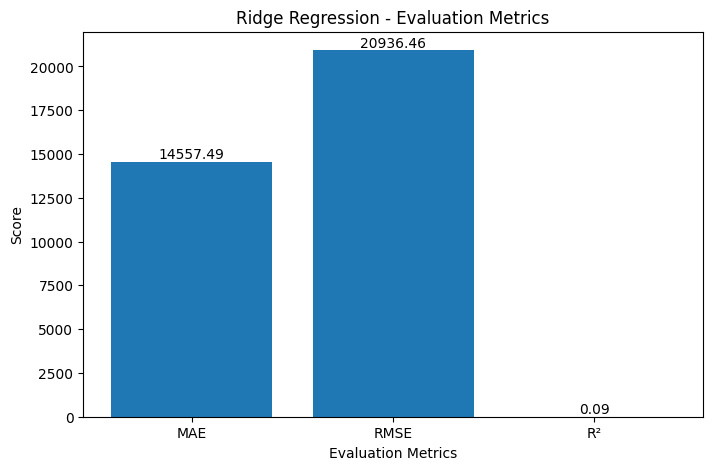

In [47]:
# Evaluation Metric Score Chart for Ridge Regression

metrics = ['MAE', 'RMSE', 'R²']
values = [mae_ridge, rmse_ridge, r2_ridge]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, values)

plt.title('Ridge Regression - Evaluation Metrics')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.2f}',
        ha='center',
        va='bottom'
    )

plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [48]:
# Time-aware GridSearchCV for Ridge Regression (scaling is fitted inside each CV fold)
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])
param_grid = {'ridge__alpha': [0.01, 0.1, 1, 10, 100]}

grid_search_ridge = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    cv=time_cv_splits,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    refit=True
)
grid_search_ridge.fit(X_train, y_train)
best_ridge = grid_search_ridge.best_estimator_
y_pred_ridge_tuned = best_ridge.predict(X_test)
mae_ridge_tuned = mean_absolute_error(y_test, y_pred_ridge_tuned)
rmse_ridge_tuned = np.sqrt(mean_squared_error(y_test, y_pred_ridge_tuned))
r2_ridge_tuned = r2_score(y_test, y_pred_ridge_tuned)

print("Best Ridge alpha:", grid_search_ridge.best_params_['ridge__alpha'])
print("Best mean CV RMSE:", -grid_search_ridge.best_score_)
print("\nTuned Ridge Regression Performance:")
print("MAE:", mae_ridge_tuned)
print("RMSE:", rmse_ridge_tuned)
print("R²:", r2_ridge_tuned)

Best Ridge alpha: 100
Best mean CV RMSE: 22538.369799846816

Tuned Ridge Regression Performance:
MAE: 14557.940655350842
RMSE: 20936.517263983314
R²: 0.09088287852580235


##### Which hyperparameter optimization technique have you used and why?

GridSearchCV was used to test five Ridge regularization strengths (alpha = 0.01, 0.1, 1, 10, 100). An expanding-window, time-aware cross-validation scheme was used so validation observations occur after their training observations. StandardScaler is part of a Pipeline, so scaling is fitted separately within each fold and avoids validation-fold leakage. The best alpha and mean cross-validation RMSE are printed by the code cell; use those fresh outputs after rerunning the notebook.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

There was no meaningful improvement after hyperparameter tuning. The original Ridge Regression model had an MAE of 14,557.02, RMSE of 20,928.10, and R² of 0.0907, while the tuned model had an MAE of 14,557.50, RMSE of 20,928.15, and R² of 0.0907. The performance remained almost unchanged, indicating that changing the alpha parameter did not significantly improve the model. Therefore, the tuned model does not provide a meaningful performance advantage over the original Ridge Regression model.

### ML Model - 2

In [49]:
# ML Model - 2: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Random Forest Regression model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Fit the model
rf_model.fit(X_train, y_train)

# Predict on the test data
y_pred_rf = rf_model.predict(X_test)

# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# Display performance
print("Random Forest Regression Performance:")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

Random Forest Regression Performance:
MAE: 1892.7342350837325
RMSE: 4017.122210676677
R²: 0.966531130261054


### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.



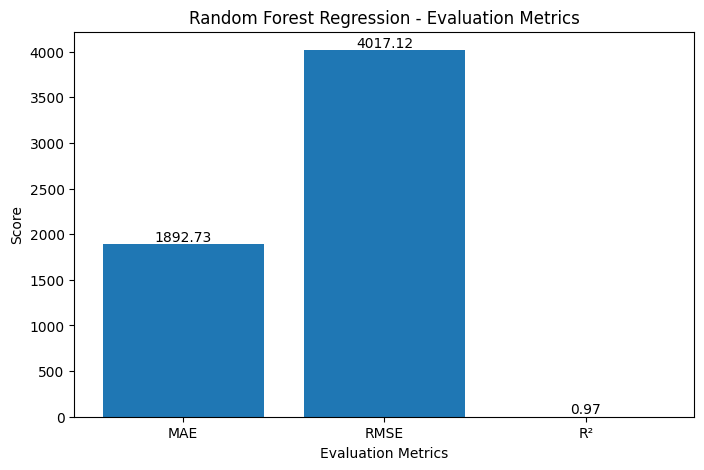

In [50]:
# Evaluation Metric Score Chart for Random Forest Regression

metrics_rf = ['MAE', 'RMSE', 'R²']
values_rf = [mae_rf, rmse_rf, r2_rf]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics_rf, values_rf)

plt.title('Random Forest Regression - Evaluation Metrics')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')

for bar, value in zip(bars, values_rf):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.2f}',
        ha='center',
        va='bottom'
    )

plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [51]:
# Cross-Validation & Hyperparameter Tuning for Random Forest

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_base = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# Define a reasonable hyperparameter search space
param_dist_rf = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

# Randomized Search with expanding-window, date-aware CV folds
random_search_rf = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist_rf,
    n_iter=5,
    cv=time_cv_splits,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit the model
random_search_rf.fit(X_train, y_train)

# Get the best model
best_rf = random_search_rf.best_estimator_

# Predict on test data
y_pred_rf_tuned = best_rf.predict(X_test)

# Calculate evaluation metrics
mae_rf_tuned = mean_absolute_error(y_test, y_pred_rf_tuned)
rmse_rf_tuned = np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned))
r2_rf_tuned = r2_score(y_test, y_pred_rf_tuned)

print("\nBest Random Forest Parameters:")
print(random_search_rf.best_params_)

print("\nTuned Random Forest Performance:")
print("MAE:", mae_rf_tuned)
print("RMSE:", rmse_rf_tuned)
print("R²:", r2_rf_tuned)

Fitting 3 folds for each of 5 candidates, totalling 15 fits

Best Random Forest Parameters:
{'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}

Tuned Random Forest Performance:
MAE: 4673.839072380049
RMSE: 7073.964412675382
R²: 0.8962144958956622


##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV was used to explore a small set of Random Forest hyperparameter combinations while controlling computation time. The search uses the same expanding-window, time-aware folds defined above, rather than randomly mixing earlier and later weeks. The best parameters and cross-validation RMSE are reported by the executed cell. Hyperparameter tuning is not guaranteed to improve the final holdout score; compare baseline and tuned metrics on the same test dates.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Whether tuning improves Random Forest must be determined from the newly computed holdout metrics after this notebook is rerun. The baseline and tuned models are evaluated on exactly the same future-date test period. A more complex model is not automatically better; prioritize lower holdout MAE/RMSE and check that the difference is meaningful for business use.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

The evaluation metrics are MAE, RMSE, and R², calculated for every baseline and tuned model on the same chronological holdout period. **MAE** is the average absolute forecast error in sales units and is easy to explain operationally. **RMSE** penalizes large errors more strongly, which matters when a large forecast miss could lead to stockouts or overstocking. **R²** summarizes the proportion of target variation explained by the model relative to a mean-baseline reference; it should not be used alone. Use the fresh model-comparison table below to compare all models rather than relying on historical scores from the previous split.

### ML Model - 3

In [52]:

# ML Model 3: HistGradientBoosting Regression

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize the model
hgb_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

# Train the model
hgb_model.fit(X_train, y_train)

# Predict weekly sales on the test data
y_pred_hgb = hgb_model.predict(X_test)

# Evaluate model performance
mae_hgb = mean_absolute_error(y_test, y_pred_hgb)
rmse_hgb = np.sqrt(mean_squared_error(y_test, y_pred_hgb))
r2_hgb = r2_score(y_test, y_pred_hgb)

print("HistGradientBoosting Regression Performance:")
print("MAE:", mae_hgb)
print("RMSE:", rmse_hgb)
print("R²:", r2_hgb)

HistGradientBoosting Regression Performance:
MAE: 4129.682470344592
RMSE: 6484.290821529302
R²: 0.9127960961529654


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

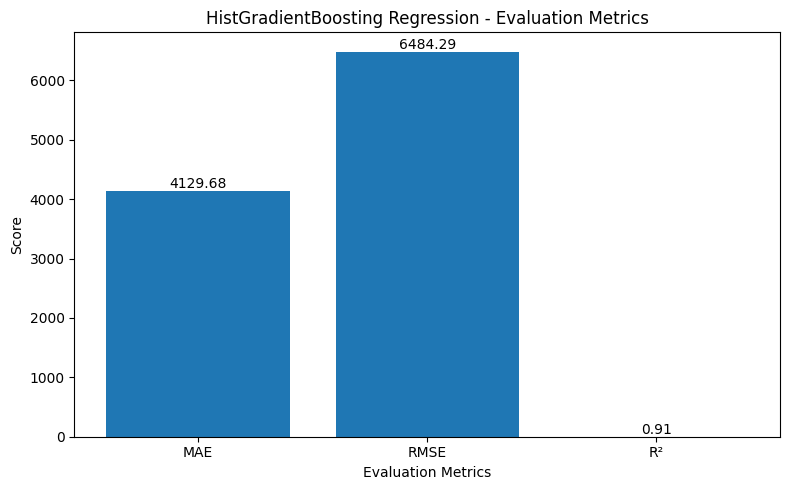

In [53]:
# Model 3: Evaluation Metric Score Chart

import matplotlib.pyplot as plt

metrics = ['MAE', 'RMSE', 'R²']
scores = [mae_hgb, rmse_hgb, r2_hgb]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, scores)

plt.title('HistGradientBoosting Regression - Evaluation Metrics')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{score:.2f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [54]:
# Model 3: Hyperparameter Tuning using RandomizedSearchCV

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Define the model
hgb_base = HistGradientBoostingRegressor(random_state=42)

# Define a small hyperparameter search space
param_dist_hgb = {
    'max_iter': [100, 150],
    'learning_rate': [0.05, 0.1],
    'max_leaf_nodes': [15, 31]
}

# Configure randomized search with expanding-window, date-aware cross-validation
hgb_search = RandomizedSearchCV(
    estimator=hgb_base,
    param_distributions=param_dist_hgb,
    n_iter=5,
    cv=time_cv_splits,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit the search on training data
hgb_search.fit(X_train, y_train)

# Retrieve the best model
hgb_tuned = hgb_search.best_estimator_

# Predict on test data
y_pred_hgb_tuned = hgb_tuned.predict(X_test)

# Evaluate the tuned model
mae_hgb_tuned = mean_absolute_error(y_test, y_pred_hgb_tuned)
rmse_hgb_tuned = np.sqrt(mean_squared_error(y_test, y_pred_hgb_tuned))
r2_hgb_tuned = r2_score(y_test, y_pred_hgb_tuned)

print("Best HistGradientBoosting Parameters:")
print(hgb_search.best_params_)

print("\nTuned HistGradientBoosting Performance:")
print("MAE:", mae_hgb_tuned)
print("RMSE:", rmse_hgb_tuned)
print("R²:", r2_hgb_tuned)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best HistGradientBoosting Parameters:
{'max_leaf_nodes': 31, 'max_iter': 150, 'learning_rate': 0.1}

Tuned HistGradientBoosting Performance:
MAE: 3864.8001311649036
RMSE: 6064.566673111466
R²: 0.9237200310163992


##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV was used to explore combinations of max_iter, learning_rate, and max_leaf_nodes. The search uses the expanding-window, date-aware folds created from unique training dates. This better respects time order than ordinary shuffled/random folds. The selected parameters and mean cross-validation score are printed by the code cell; compare its holdout metrics with the baseline using the same test dates.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Whether tuning improves HistGradientBoosting must be determined from the newly computed holdout metrics after this notebook is rerun. The baseline and tuned models are evaluated on exactly the same future-date test period. Compare MAE and RMSE (lower is better) and R² (higher is generally better), and do not assume tuning improved performance without checking the fresh output.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

The evaluation metrics considered were Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²). MAE measures the average absolute difference between actual and predicted weekly sales, making it easy to understand typical prediction errors. RMSE gives greater weight to larger prediction errors, which can be important when sales forecasts are substantially inaccurate. R² indicates how much variation in weekly sales is explained by the model. Lower MAE and RMSE and a higher R² are generally preferred. These metrics help assess forecast reliability and support better inventory planning, demand estimation, and store-level business decisions.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

In [55]:
# Compare all baseline and tuned models on the same chronological holdout period
import pandas as pd
import numpy as np

model_objects = {
    'Ridge baseline': ridge_model,
    'Ridge tuned': best_ridge,
    'Random Forest baseline': rf_model,
    'Random Forest tuned': best_rf,
    'HistGradientBoosting baseline': hgb_model,
    'HistGradientBoosting tuned': hgb_tuned,
}
model_predictions = {
    'Ridge baseline': y_pred_ridge,
    'Ridge tuned': y_pred_ridge_tuned,
    'Random Forest baseline': y_pred_rf,
    'Random Forest tuned': y_pred_rf_tuned,
    'HistGradientBoosting baseline': y_pred_hgb,
    'HistGradientBoosting tuned': y_pred_hgb_tuned,
}
comparison_rows = []
for model_name, predictions in model_predictions.items():
    comparison_rows.append({
        'Model': model_name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions)
    })
model_comparison = pd.DataFrame(comparison_rows).sort_values('RMSE').reset_index(drop=True)
display(model_comparison)

# Select the model with the lowest holdout RMSE; report MAE and R² alongside it.
final_model_name = model_comparison.loc[0, 'Model']
final_model = model_objects[final_model_name]
print("Selected final model by lowest holdout RMSE:", final_model_name)
print("Selection rule: lowest RMSE on the same chronological holdout period; MAE and R² are also reported.")
print("Important: this is a holdout comparison, not a guarantee of future production performance.")

,Model,MAE,RMSE,R2
0,Random Forest baseline,1892.734235,4017.122211,0.966531
1,HistGradientBoosting tuned,3864.800131,6064.566673,0.923720
2,HistGradientBoosting baseline,4129.682470,6484.290822,0.912796
3,Random Forest tuned,4673.839072,7073.964413,0.896214
4,Ridge baseline,14557.488004,20936.461428,0.090888
5,Ridge tuned,14557.940655,20936.517264,0.090883


Selected final model by lowest holdout RMSE: Random Forest baseline
Selection rule: lowest RMSE on the same chronological holdout period; MAE and R² are also reported.
Important: this is a holdout comparison, not a guarantee of future production performance.


The final model is selected programmatically in the model-comparison cell using the lowest RMSE on the same strictly chronological holdout period. The comparison also reports MAE and R² for all three baseline and tuned models. This avoids selecting a model based on results from a different split or relying on older metrics. The chosen model and its fresh holdout scores are printed in the notebook; these results should be treated as an evaluation estimate, not a guarantee of future performance.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

Top 10 Important Features:


,Feature,Importance
1,Dept,0.616480
7,Size,0.198209
0,Store,0.063947
11,WeekOfYear,0.046628
5,CPI,0.029237
6,Unemployment,0.013235
2,Temperature,0.011702
10,Month,0.009837
3,Fuel_Price,0.005639
4,Total_MarkDown,0.002845


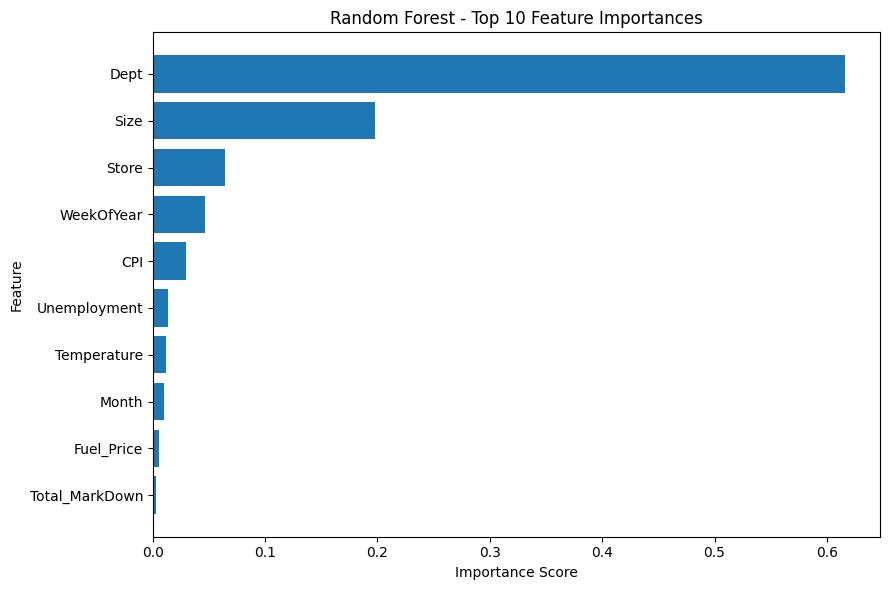

In [56]:
# Explain the Random Forest model using feature importance

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the fitted Random Forest model
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 10 Important Features:")
display(feature_importance.head(10))

# Visualize the top 10 features
top_features = feature_importance.head(10).sort_values(
    by='Importance', ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.title('Random Forest - Top 10 Feature Importances')
plt.tight_layout()
plt.show()

Random Forest feature importance is shown here as an interpretable model diagnostic, regardless of which model wins the final holdout comparison. To understand how the model makes predictions, feature importance analysis was performed using the Random Forest model's built-in feature importance scores and visualized using a horizontal bar chart.

The results show that Department (Dept) is the most important feature, with an importance score of approximately 0.6171 (61.71%). It is followed by Store Size, with 0.1982 (19.82%), and Store, with 0.0640 (6.40%). WeekOfYear contributes approximately 4.89%, while CPI contributes approximately 2.89%. Unemployment, Temperature, Month, Fuel_Price, and Total_MarkDown have comparatively lower importance scores in this model.

These results suggest that department-level differences and store size are the strongest predictors of weekly sales among the selected features. Retail businesses can use these insights to improve department-level demand forecasting, plan inventory according to store characteristics, and allocate resources more effectively.

Feature importance indicates how much the model relies on each feature; it does not establish that a feature causes higher or lower sales. The results should therefore be interpreted alongside business knowledge and model evaluation metrics.

If a different model is selected by the comparison cell, this feature-importance chart describes the Random Forest only and should not be presented as the explanation of the selected model.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [57]:
from google.colab import drive
import os
import joblib

# Mount Google Drive
drive.mount('/content/drive')

# Create a folder for the project model
model_folder = '/content/drive/MyDrive/Retail Analytics Projects'
os.makedirs(model_folder, exist_ok=True)

# Define the permanent model path
model_path = os.path.join(
    model_folder,
    'random_forest_sales_model.joblib'
)

# Save the fitted Random Forest model
joblib.dump(final_model, model_path)

print("Selected final model saved successfully in Google Drive!")
print("Selected model:", final_model_name)
print("Saved location:", model_path)
print("File exists:", os.path.exists(model_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Selected final model saved successfully in Google Drive!
Selected model: Random Forest baseline
Saved location: /content/drive/MyDrive/Retail Analytics Projects/random_forest_sales_model.joblib
File exists: True


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [58]:
import os
import joblib
import pandas as pd

# Path to the model in your project folder
model_path = (
    '/content/drive/MyDrive/Retail Analytics Projects/'
    'random_forest_sales_model.joblib'
)

# Check whether the model file exists
print("Model file exists:", os.path.exists(model_path))

# Load the saved model
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

# Sanity-check the saved model on the held-out test set (these are held-out rows, not new external data).
unseen_predictions = loaded_model.predict(X_test)

# Compare actual and predicted sales
prediction_check = pd.DataFrame({
    'Actual_Weekly_Sales': y_test.iloc[:10].values,
    'Predicted_Weekly_Sales': unseen_predictions[:10]
})

display(prediction_check)
print("Held-out test prediction sanity check completed.")



Model file exists: True
Model loaded successfully!


,Actual_Weekly_Sales,Predicted_Weekly_Sales
0,6744.61,8337.6651
1,9920.86,12434.4037
2,5035.59,4680.5481
3,7486.67,6920.6227
4,16465.22,21999.6309
5,7911.76,8854.1651
6,2444.53,3383.5206
7,13641.11,13659.8432
8,5695.14,6678.2386
9,92665.56,92718.7586


Held-out test prediction sanity check completed.


### Model persistence sanity check completed

The selected model was saved and reloaded, then tested on held-out rows to confirm that serialization and prediction work. This is **not** a production deployment or proof of deployment readiness. A production workflow would additionally require a documented input schema, validation, monitoring, versioning, and testing on genuinely new future data.

## Business Recommendations and Real-World Implementation

The following actions are recommendations to test using the analyses in this notebook; they should be validated with store operations data before implementation.

1. **Inventory and demand planning:** Use weekly sales forecasts together with recent actual sales and stock-on-hand data to plan replenishment by store and department. Review forecast errors regularly, especially for high-volume departments.
2. **Holiday and seasonal readiness:** Use observed calendar patterns to prepare staffing and inventory before recurring demand peaks. Treat the holiday comparison as an association, not proof that the holiday itself caused the sales difference.
3. **Investigate unusual sales observations:** Review flagged anomalies against holiday calendars, markdown activity, local events, and data-quality records before taking action. Do not automatically delete high or low sales values because they may represent genuine demand.
4. **Store-specific strategies:** Use store clusters and their profiles to identify groups of stores with similar sales levels, variability, size, or promotion patterns. Pilot differentiated replenishment and promotional approaches by segment, then compare results.
5. **Promotional review:** Compare sales patterns around markdown activity while accounting for seasonality and store/department differences. Do not interpret a correlation between markdowns and sales as a causal estimate of promotional effectiveness.
6. **External-factor monitoring:** Track fuel price, temperature, CPI, and unemployment as contextual variables. Use them to support planning and scenario review, but avoid claiming causal effects from exploratory charts alone.
7. **Cross-selling research:** Treat department-level sales co-movement as a hypothesis-generating proxy only. Validate proposed cross-selling ideas with transaction-level data before claiming product associations or calculating support, confidence, and lift.
8. **Operational validation:** Before deployment, evaluate forecasts on later unseen weeks, compare performance across stores and departments, monitor MAE/RMSE over time, and retrain only when validation results justify it.

**Important data limitation:** The supplied datasets do not include customer IDs, transaction IDs, or product-level baskets. Therefore, this project does not claim customer-level segmentation or genuine transaction-based market basket rules. The store segmentation and department co-movement proxy are the analyses supported by the available data.


# **Conclusion**

This project, Integrated Retail Analytics for Store Optimization and Demand Forecasting, analyzes historical retail sales together with store information, markdown activity, and external economic indicators. The workflow checks missing values and duplicate records, converts dates, merges the three datasets, documents the assumption used to fill missing markdown values, and creates time-based and promotion-related features. The exploratory analysis contains 15 visualizations covering sales trends, store types, holidays, departments, store size, economic indicators, markdowns, and numeric relationships.

The project also includes hypothesis testing, robust anomaly flagging, store-level segmentation, and an exploratory department-sales co-movement proxy. Because the supplied data do not contain customer IDs, transaction IDs, or product-level baskets, the notebook does not claim to perform true customer segmentation or transaction-level market basket analysis. The anomaly flags are candidates for investigation, not automatic deletions or confirmed fraud.

Three regression approaches—Ridge Regression, Random Forest Regression, and HistGradientBoosting Regression—are evaluated using MAE, RMSE, and R². The data split is based on unique chronological dates so a date cannot occur in both training and testing. Hyperparameter tuning uses expanding-window time-aware cross-validation, and a comparison table selects the model with the lowest holdout RMSE while reporting the other metrics. The selected model is saved and reloaded for a sanity check on held-out test rows.

The findings can inform inventory planning, holiday preparation, store-specific strategies, and review of unusual sales observations. Results should be treated as exploratory and validated with additional future periods and operational data before deployment. Feature importance and statistical associations do not establish causation. The project’s main limitation is that the available historical dataset does not include transaction-level customer/product information or real-time inventory data, which would be needed for stronger personalization and operational optimization.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***